# 통계 파일별 1 · 02 데이터 요약과 시각화

**한 줄 요약** · 강의 PDF 131쪽을 코드로 다시 만들어, 데이터 유형 → 도수분포표 → 대표값 · 퍼짐 → 그래프 5종을 고르고 읽는 법까지 정리

- **원본** · `4. statistics/01_강의자료/02_데이터 요약과 시각화.pdf` (원본 파일은 그대로 둠)
- **종합 정리본** · 통계 전체 정리는 아직 없음 · 같은 PDF 사본은 `00. 전체 필수숙지해야하는 것들/04_통계·시각화/`

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. 변수를 범주형(명목 · 순서) · 이산형 · 연속형으로 나누고 맞는 그래프를 고른다
2. 도수분포표 6단계를 코드로 만들고 최빈 구간 · 중앙값 구간 · 누적 비율을 읽는다
3. 평균 · 중앙값 · 최빈값 · 분산 · 표준편차 · IQR을 직접 계산하고 언제 무엇을 쓸지 말한다
4. 히스토그램 · 박스플롯으로 분포의 중심 · 퍼짐 · 모양 · 이상점 후보를 읽는다
5. 막대 · 원 · 산점도 · 선그래프 · 히트맵을 질문에 맞게 고르고 해석한다

## 어디에 쓰나

*실제 상황 → 이 권에서 배우는 것*

- **학습 데이터를 받아 처음 살펴볼 때 (EDA)** · 유형 확인 · `describe()` · 히스토그램 (1 · 3 · 4장)
- **입력을 정규화할 때 평균 · 표준편차가 필요할 때** · 분산 · 표준편차 계산 (4-2)
- **이상한 값을 지울지 판단할 때** · IQR · fence · 박스플롯 (4-3 · 7장)
- **학습 곡선 · 혼동 행렬을 그릴 때** · 선그래프 · 히트맵 (8장)

## 학습 지도

<img src="images/st1_map.png" alt="02_데이터 요약과 시각화 학습 지도" width="800">

**예상 학습 시간** · 개념 1시간 30분 + 실습 40분 (내려받는 데이터 없음)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">장</th><th style="text-align: left;">제목</th><th style="text-align: left;">이 장의 질문</th></tr>
</thead>
<tbody>
<tr><td>0</td><td>준비</td><td>실행 환경 · 원본 강의 흐름</td></tr>
<tr><td>1</td><td>데이터 유형</td><td>이 열은 어떤 유형이고, 그래서 어떤 요약 · 그래프를 써야 하는가?</td></tr>
<tr><td>2</td><td>도수분포표</td><td>숫자 200개를 어떻게 표 하나로 줄이고, 그 표에서 무엇을 읽는가?</td></tr>
<tr><td>3</td><td>히스토그램</td><td>평균 하나로 가려지는 분포의 모양을 히스토그램으로 어떻게 읽는가?</td></tr>
<tr><td>4</td><td>대표값과 퍼짐 (보강)</td><td>데이터를 숫자 몇 개로 요약할 때 무엇을 계산하고, 극단값에는 무엇이 강한가?</td></tr>
<tr><td>5</td><td>변수 유형별 차트 고르기</td><td>질문을 받으면 변수 몇 개 · 어떤 유형인지로 그래프를 어떻게 바로 고르는가?</td></tr>
<tr><td>6</td><td>막대그래프 · 원그래프</td><td>범주형 한 변수의 개수와 비율은 막대와 원 중 무엇으로 보여야 하는가?</td></tr>
<tr><td>7</td><td>박스플롯</td><td>평균이 같은 두 집단의 차이와 이상점 후보를 한 그림으로 어떻게 보는가?</td></tr>
<tr><td>8</td><td>산점도 · 선그래프 · 히트맵</td><td>두 수치의 관계, 시간에 따른 변화, 두 범주 조합의 값을 각각 어떻게 보는가?</td></tr>
<tr><td>9</td><td>종합 실습</td><td>처음 받은 결제 데이터를 숫자와 그래프로 어떻게 한 번에 요약하는가?</td></tr>
<tr><td>—</td><td>마무리 · 부록</td><td>오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td></tr>
</tbody></table>

---
## 0. 준비

강의 PDF에는 코드가 없어서, 슬라이드의 표 · 그래프 숫자를 노트북 안에서 같은 값으로 만들어 실습함. **셀은 위에서부터 차례로 실행**.

*항목 → 설정*

- **라이브러리** · NumPy · pandas · matplotlib
- **seed** · `np.random.default_rng(0)` 하나로 모든 무작위 데이터를 만듦 (같은 NumPy 버전에서 매번 같은 값)
- **글꼴** · `Malgun Gothic` (Windows 기본 · 그래프 한글)
- **데이터** · 키 200명 · 결제 100건 · 두 반 점수 · 광고비 · 카페 매출 · 지역별 월 매출 (모두 코드로 생성)
- **범위** · PDF 131쪽 전부 · 강의가 '진행 예정'으로 남긴 대표값 · 분산은 4장에서 보강

**실행 흐름**

1. `numpy` · `pandas` · `matplotlib` 불러오기
2. 한글 글꼴 · 음수 기호 · 해상도 설정
3. 난수 생성기 seed 고정

In [1]:
# 라이브러리 · 그래프 한글 · 재현성
# 왜 · 한글이 네모로 깨지지 않게 하고, 난수 seed를 고정해 같은 환경에서 같은 가짜 데이터를 얻기 위해
import numpy as np               # 숫자 계산 · 난수
import pandas as pd              # 표 · 도수분포표
import matplotlib.pyplot as plt  # 그래프

plt.rcParams["font.family"] = "Malgun Gothic"               # 그래프 한글 (Windows 기본 글꼴)
plt.rcParams["axes.unicode_minus"] = False                  # 음수 기호 깨짐 방지
plt.rcParams["figure.dpi"] = 80                             # 노트북 안 그림 크기
rng = np.random.default_rng(0)                              # 난수 고정 → 같은 버전에서 같은 데이터
print("NumPy", np.__version__, "| pandas", pd.__version__)  # 버전 기록

NumPy 2.4.6 | pandas 3.0.3


### 원본 강의 흐름 (131쪽)

- 1 ~ 5쪽 · 데이터 분석가의 업무 (요약 · 설명 · 예측) · 숫자 더미 → 요약 도구 (도수분포표 · 히스토그램 · 대표값)
- 6 ~ 13쪽 · 데이터 유형 (양적 = 이산 · 연속, 질적 = 범주) · 유형별 그래프 · 미니퀴즈
- 14 ~ 22쪽 · 도수분포표 6단계 · 키 200명 표 · 인사이트 · 히스토그램으로 변환
- 23 ~ 34쪽 · 히스토그램 (정의 · 필요성 · 사용처 · 읽을 것 4가지 · bin 주의)
- 35 ~ 51쪽 · 변수 · 범주형 · 연속형 · 이산형 · 차트 치트 1 · 2 (일변량 · 이변량 · 다변량)
- 52 ~ 66쪽 · 막대그래프 · 원그래프 · 67 ~ 84쪽 · 박스플롯 (다섯 숫자 · IQR · fence · 같은 평균 다른 분산)
- 85 ~ 98쪽 · 산점도 · 99 ~ 110쪽 · 선그래프 · 111 ~ 124쪽 · 히트맵 · 125 ~ 131쪽 · 차트 고르는 기준 · 결론

**원본 힌트**

- 강의 4쪽의 '대표값(진행 예정)'과 26 · 31쪽의 평균 · 중앙값 · 분산 · 표준편차는 설명이 없음 → 4장에서 보강
- 원본 오류 (이 노트북에서는 고쳐 씀) · 18쪽 표의 넷째 열 이름 '누적도수'는 값이 비율이라 '누적상대도수'
- 원본 표기 · 19쪽 '96.5%' 앞뒤에 굵게 표시 기호(별표 두 개)가 그대로 보임 → 기호 없이 씀
- 원본 띄어쓰기 · 26쪽 '흩어져있냐 · 쏠려있냐' → '흩어져 있냐 · 쏠려 있냐' · 92쪽 '점 점 멀어지나봐' → '점점 멀어지나 봐'
- 원본 문장 · 59쪽 '카페들을 할 때' → '카페를 할 때' · 116쪽 '피크타임 패턴을 색' → '피크타임 패턴을 색으로 확인'

---
## 1. 데이터 유형

> **이 장의 흐름**
>
> - 강의 미니퀴즈의 변수 4개를 양적 · 질적으로 나누고, 숫자로 적힌 범주를 확인
> - 그다음 같은 결제 데이터를 맞는 그래프와 틀린 그래프로 그려 차이를 봄

<img src="images/st1_types.png" alt="변수 유형 나무와 맞는 그래프" width="763">

**파이프라인 위치** · ① 데이터 이해 (EDA 첫 단계)

### 1-1. `A` 양적(이산 · 연속) vs 질적(범주) · `pd.api.types.is_numeric_dtype` · `value_counts` <sub>PDF 6 ~ 8 · 12 · 37 ~ 43쪽</sub>

> 🎯 **혈압 · 혈액형 · 걸음 수 · 브랜드는 각각 어떤 유형이고, 숫자 코드는 왜 범주인가?**

💡 **쉽게 말하면**

- 숫자로 **잴 수 있으면** 양적, **종류만 가르면** 질적(범주).
- 양적 중 셀 수 있으면 이산형(걸음 수), 중간값이 무한하면 연속형(혈압).

**실행 흐름**

1. 미니퀴즈 표 만들기
2. 열마다 숫자 열인지 확인 · 세부 유형 붙이기
3. 결제수단 코드의 평균 vs 개수

**먼저 예측** · 결제수단 코드(1 = 카드 · 2 = 현금 · 3 = 간편결제)의 평균 1.57은 뜻이 있을까? — 답은 코드 실행 결과 아래에

In [2]:
# 강의 12쪽 미니퀴즈: 변수 4개를 양적(수치) · 질적(범주)으로 나누기
# 왜 · 변수 유형을 먼저 정해야 맞는 요약 · 그래프를 고를 수 있기 때문에
quiz = pd.DataFrame({                                  # 열 = 변수 · 행 = 사람 3명
    "혈압": [118.5, 125.0, 132.4],                     # mmHg · 소수 가능
    "혈액형": ["A", "O", "AB"],                        # 종류만 있음
    "걸음수": [10000, 8421, 12030],                    # 하루 걸음 · 셀 수 있음
    "브랜드": ["삼성", "애플", "삼성"],                # 종류만 있음
})
# 강의 7 · 8 · 42쪽 기준
detail = {"혈압": "연속형", "혈액형": "명목형", "걸음수": "이산형", "브랜드": "명목형"}
for col in quiz.columns:                               # 열마다
    is_num = pd.api.types.is_numeric_dtype(quiz[col])  # 숫자 열인가
    kind = "양적(수치)" if is_num else "질적(범주)"    # 큰 분류
    print(f"{col} | {kind} · {detail[col]}")           # 큰 분류 · 세부 유형


# 숫자로 적혀 있어도 범주인 경우: 결제수단 코드 1 = 카드 · 2 = 현금 · 3 = 간편결제
# 왜 · 숫자 모양만 보고 평균을 내는 실수를 막기 위해
pay_code = pd.Series([1, 2, 1, 1, 3, 1, 2])                            # 숫자지만 '종류'
print("코드 평균:", round(pay_code.mean(), 2), "← 뜻 없는 숫자")       # 1.57 = ?
print("코드별 개수:", pay_code.value_counts().sort_index().to_dict())  # 범주는 개수로 요약

혈압 | 양적(수치) · 연속형
혈액형 | 질적(범주) · 명목형
걸음수 | 양적(수치) · 이산형
브랜드 | 질적(범주) · 명목형
코드 평균: 1.57 ← 뜻 없는 숫자
코드별 개수: {1: 4, 2: 2, 3: 1}


**결과** · 예측 정답은 뜻 없음 — 코드는 이름표라 개수(`value_counts`)로 요약해야 함

- `혈압 | 양적(수치) · 연속형` — 소수까지 잴 수 있음
- `걸음수 | 양적(수치) · 이산형` — 1보 단위로 셈
- `혈액형 | 질적(범주) · 명목형` — 종류만 있음 · 브랜드도 같음
- `코드 평균: 1.57 ← 뜻 없는 숫자` — '카드와 현금 사이'라는 결제수단은 없음
- `코드별 개수: {1: 4, 2: 2, 3: 1}` — 범주는 개수 · 비율로 요약

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>명목형 범주</td><td>순서 없는 종류 (혈액형 · 브랜드)</td><td>개수 · 비율 → 막대 · 원그래프</td></tr>
<tr><td>순서형 범주</td><td>순서 있는 종류 (만족도 상 · 중 · 하)</td><td>순서대로 놓은 막대</td></tr>
<tr><td>이산형</td><td>셀 수 있는 숫자 (방문 횟수 · 걸음 수)</td><td>값이 적으면 막대 · 많으면 히스토그램</td></tr>
<tr><td>연속형</td><td>중간값이 무한한 숫자 (키 · 금액 · 시간)</td><td>평균 · 표준편차 · 히스토그램 · 박스플롯</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 숫자 dtype이라고 다 양적이 아님 · 코드 · 우편번호 · 회원번호는 범주
> - 이산형인지는 소수점 유무가 아니라 '셀 수 있는가'로 판단 (강의 42쪽)

> ✅ **한 줄 정리** · 숫자로 잴 수 있으면 양적(이산 · 연속), 종류만 가르면 범주이며, 숫자로 적힌 코드도 범주라 평균이 아니라 개수로 요약한다.

**딥러닝 코드에서는**

- 범주형 열은 번호 → one-hot · 임베딩으로, 연속형 열은 정규화해서 모델에 넣음
- 분류 라벨 `y`(0 · 1 · 2)는 숫자지만 범주 → 평균을 내지 않고 `bincount`로 개수 확인

### 1-2. `A` 유형에 맞는 그래프 vs 틀린 그래프 · `plt.subplots` · `ax.bar` · `ax.hist` <sub>PDF 9 ~ 11쪽</sub>

> 🎯 **결제수단과 결제금액을 같은 막대그래프로 그리면 무엇이 문제인가?**

💡 **쉽게 말하면**

- 범주는 **종류마다 막대 1개** · 연속형은 **구간마다 막대 1개**.
- 금액을 손님마다 막대로 그리면 막대만 수십 개라 패턴이 안 보임.

**실행 흐름**

1. 결제 100건 만들기 (카드 70 · 현금 30)
2. 범주 개수 · 금액의 서로 다른 값 수 세기
3. 맞는 그래프 2개 + 틀린 그래프 1개

**먼저 예측** · 결제금액 100건 중 서로 다른 금액은 몇 개쯤일까? — 답은 코드 실행 결과 아래에

결제수단 개수: {'카드': 70, '현금': 30}
결제금액 서로 다른 값: 90 개


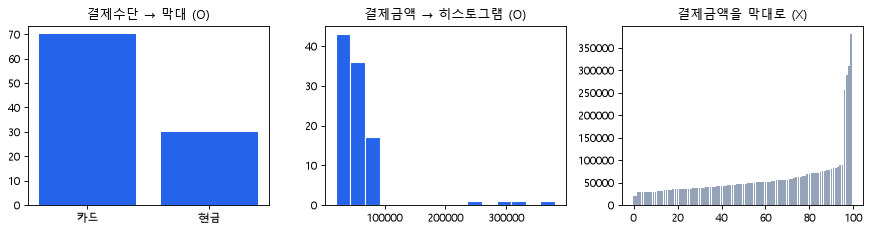

In [3]:
# 결제 100건: 결제수단(범주) · 결제금액(연속) — 강의 9 ~ 11쪽 예
# 왜 · 범주 · 연속 변수가 함께 있는 실제 데이터 모양을 만들기 위해
# 대부분 5만 원 근처 · 큰 결제 4건
amount = np.r_[rng.lognormal(10.7, 0.35, 96), [255000, 290000, 310000, 380000]]
pay = pd.DataFrame({"결제수단": ["카드"] * 70 + ["현금"] * 30,    # 범주형
                    "결제금액": amount.round(-2)})                # 연속형 · 100원 단위
counts = pay["결제수단"].value_counts()                           # 범주 → 개수
print("결제수단 개수:", counts.to_dict())                         # 막대 2개면 충분
print("결제금액 서로 다른 값:", pay["결제금액"].nunique(), "개")  # 막대로 그리면 이만큼 막대


# 맞는 그래프 (막대 · 히스토그램) vs 틀린 그래프 (금액마다 막대)
# 왜 · 변수 유형에 맞지 않는 그래프가 왜 읽기 어려운지 나란히 보기 위해
fig, axes = plt.subplots(1, 3, figsize=(11, 3))                               # 가로 3칸
axes[0].bar(counts.index, counts.values, color="#2563eb")                     # 범주 → 막대
axes[0].set_title("결제수단 → 막대 (O)")                                      # 맞는 짝
axes[1].hist(pay["결제금액"], bins=15, color="#2563eb", edgecolor="white")    # 연속 → 구간별 개수
axes[1].set_title("결제금액 → 히스토그램 (O)")                                # 맞는 짝
axes[2].bar(range(len(pay)), pay["결제금액"].sort_values(), color="#94a3b8")  # 손님 1명씩 막대
axes[2].set_title("결제금액을 막대로 (X)")                                    # 패턴이 안 보임
plt.tight_layout()                                                            # 칸 간격 정리
plt.show()                                                                    # 그림 출력

**결과** · 예측 정답은 90개 — 금액마다 막대를 그리면 막대가 90개 넘게 생김

- `결제수단 개수: {'카드': 70, '현금': 30}` — 범주 2개 → 막대 2개면 끝
- `결제금액 서로 다른 값: 90 개` — 거의 손님마다 다른 금액 → 구간으로 묶어야 함
- 그림 · 왼쪽 막대와 가운데 히스토그램은 한눈에 읽히고, 오른쪽은 손님 1명씩이라 읽을 수 없음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>막대그래프 <code>ax.bar</code></td><td>범주마다 막대 · 막대 사이 간격</td><td>결제수단 · 혈액형</td></tr>
<tr><td>히스토그램 <code>ax.hist</code></td><td>값 구간마다 막대 · 막대가 붙어 있음</td><td>결제금액 · 키 · 대기시간</td></tr>
<tr><td>값마다 막대 (틀림)</td><td>관측값 수만큼 막대</td><td>쓰지 않음</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 범주를 히스토그램으로 그리면 '구간'이 없어 이상한 그림 (강의 11쪽)
> - 연속형을 막대로 그리면 '고객 1명씩' 막대가 됨

> ✅ **한 줄 정리** · 범주형은 종류별 막대그래프, 연속형은 구간별 히스토그램으로 그려야 패턴이 보이고, 유형을 잘못 고르면 잘못된 인사이트가 나온다.

**딥러닝 코드에서는**

- 클래스 개수 확인 = 막대 · 픽셀 값 · 손실 값 분포 = 히스토그램
- `plt.subplots(1, 3)`으로 여러 그래프를 나란히 비교 (통계 파일별 2의 3장)

---
## 2. 도수분포표

> **이 장의 흐름**
>
> - 강의 표와 같은 키 200명 데이터를 만들어 도수분포표 6단계를 코드로 따라 함
> - 그다음 표에서 인사이트 3가지를 읽고, 표를 히스토그램으로 바꿈

<img src="images/st1_freq.png" alt="숫자 더미 → 구간별 도수 → 누적 비율" width="778">

**파이프라인 위치** · ① 데이터 이해 → ② 요약

### 2-1. `A` 도수분포표 6단계 · `pd.cut` · `value_counts` · `cumsum` <sub>PDF 14 ~ 18쪽</sub>

> 🎯 **키 200명을 5cm 구간으로 묶으면 구간마다 몇 명이고, 누적하면 어떻게 되는가?**

💡 **쉽게 말하면**

- 사람을 **키 구간별 바구니**에 나눠 담고 바구니마다 개수를 셈.
- 개수 ÷ 전체 = 비율, 위에서부터 더하면 누적.

**실행 흐름**

1. 최솟값 · 최댓값 (범위)
2. `pd.cut`으로 5cm 구간 나누기
3. 도수 → 상대도수 → 누적도수 → 누적상대도수

**먼저 예측** · 가장 많은 학생이 모인 구간과 그 도수는? — 답은 코드 실행 결과 아래에

In [4]:
# 여중학생 200명의 키 (강의 15 · 17 · 18쪽: 145 ~ 173cm · 구간 5cm · 도수 1 · 15 · 54 · 84 · 39 · 7)
# 왜 · 강의 도수분포표와 같은 분포의 데이터를 만들어 숫자를 맞춰 보기 위해
lows, ns = [145, 150, 155, 160, 165, 170], [1, 15, 54, 84, 39, 7]  # 구간 시작 · 강의 표의 도수
height = np.concatenate([rng.uniform(lo, lo + (3 if lo == 170 else 5), n)  # 마지막 구간은 173cm까지
                         for lo, n in zip(lows, ns)]).round(2)     # 소수 둘째 자리
rng.shuffle(height)                                                # 순서 섞기 (실제 데이터처럼)
print("1단계 범위:", height.min(), "~", height.max(), "| 학생 수:", height.size)  # 최솟값 · 최댓값


# 2 ~ 6단계: 구간 나누기 → 계급값 → 도수 → 상대도수 → 누적
# 왜 · 도수분포표를 손계산 순서대로 만들어 각 열의 뜻을 이해하기 위해
bins = [145, 150, 155, 160, 165, 170, 175]               # 5cm 간격 경계
cut = pd.cut(height, bins=bins, right=False)             # [150, 155)처럼 왼쪽 포함 · 오른쪽 제외
freq = cut.value_counts().sort_index().to_frame("도수")  # 구간별 개수 (구간 순서대로)
freq.index = [f"{b}~{b + 5}" for b in bins[:-1]]         # 표에 보일 이름
freq.insert(0, "계급값", [b + 2.5 for b in bins[:-1]])   # 구간의 가운데
freq["상대도수"] = freq["도수"] / freq["도수"].sum()     # 도수 ÷ 전체
freq["누적도수"] = freq["도수"].cumsum()                 # 개수 누적
freq["누적상대도수"] = freq["상대도수"].cumsum()         # 비율 누적
print(freq.round(3))                                     # 도수분포표

1단계 범위: 149.45 ~ 172.8 | 학생 수: 200
           계급값  도수   상대도수  누적도수  누적상대도수
145~150  147.5   1  0.005     1   0.005
150~155  152.5  15  0.075    16   0.080
155~160  157.5  54  0.270    70   0.350
160~165  162.5  84  0.420   154   0.770
165~170  167.5  39  0.195   193   0.965
170~175  172.5   7  0.035   200   1.000


**결과** · 예측 정답은 160~165 구간 · 84명 (전체의 0.420)

- `1단계 범위: 149.45 ~ 172.8 | 학생 수: 200` — 강의 설정과 같은 범위 · 같은 인원
- `160~165  162.5  84  0.420   154   0.770` — 가장 큰 도수 · 여기까지 누적 77%
- `165~170  167.5  39  0.195   193   0.965` — 170cm 미만이 0.965 (강의 19쪽 96.5%)
- `170~175  172.5   7  0.035   200   1.000` — 마지막 누적 = 전체 200명 · 비율 1

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>도수</td><td>구간 안의 개수</td><td>어느 구간이 많은지</td></tr>
<tr><td>상대도수</td><td>도수 ÷ 전체 (합 = 1)</td><td>크기가 다른 집단 비교</td></tr>
<tr><td>누적도수</td><td>앞 구간부터 개수를 더함</td><td>'몇 명 이하'를 셀 때</td></tr>
<tr><td>누적상대도수</td><td>앞 구간부터 비율을 더함</td><td>중앙값 구간 · 'n% 미만' 찾기</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `pd.cut`의 기본은 오른쪽 포함 `(150, 155]` · 강의처럼 왼쪽 포함은 `right=False`
> - 강의 18쪽 넷째 열은 값이 비율이므로 이름이 '누적상대도수'여야 함

> ✅ **한 줄 정리** · 도수분포표는 범위 → 구간 → 계급값 → 도수 → 상대도수 → 누적 순서로 만들며, pd.cut과 value_counts로 한 번에 만들 수 있다.

**딥러닝 코드에서는**

- `np.histogram`과 같은 계산 · 픽셀 값 · 예측 확률을 구간별로 셀 때
- 구간 나누기(binning)는 연속형 특성을 범주로 바꾸는 전처리

### 2-2. `A` 도수분포표에서 읽을 것 3가지 · `idxmax` · `argmax` <sub>PDF 19쪽</sub>

> 🎯 **표만 보고 최빈 구간 · 중앙값 구간 · '170cm 미만 비율'을 어떻게 찾는가?**

💡 **쉽게 말하면**

- 최빈 구간 = 도수가 가장 큰 행.
- 중앙값 구간 = 누적상대도수가 **처음 0.5를 넘는** 행.

**실행 흐름**

1. 도수 최댓값의 행
2. 누적상대도수 ≥ 0.5인 첫 행
3. 170 미만 상대도수 합 · 원자료와 비교

**먼저 예측** · 중앙값 구간은 누적상대도수가 0.350인 행일까, 0.770인 행일까? — 답은 코드 실행 결과 아래에

In [5]:
# 도수분포표에서 읽을 것 3가지 (강의 19쪽)
# 왜 · 표에서 최빈 구간 · 중앙값 구간 · 누적 비율을 바로 읽어 내기 위해
mode_bin = freq["도수"].idxmax()                                 # 도수가 가장 큰 구간
median_bin = freq.index[(freq["누적상대도수"] >= 0.5).argmax()]  # 누적 비율이 처음 0.5 이상
below_170 = freq.loc["145~150":"165~170", "상대도수"].sum()      # 170cm 미만 구간 합
print(f"최빈 구간: {mode_bin} ({freq.loc[mode_bin, '상대도수']:.1%})")  # 가장 많이 모인 곳
print(f"중앙값 구간: {median_bin}")                              # 100번째 · 101번째 학생이 있는 곳
print(f"170cm 미만: {below_170:.1%}")                            # 누적상대도수 0.965


# 원자료로 확인: 표에서 읽은 값과 맞는가
# 왜 · 구간으로 요약한 값이 원자료와 얼마나 맞는지 검증하기 위해
# 표 ↔ 원자료
print("실제 중앙값:", np.median(height), "| 170 미만 실제 비율:", (height < 170).mean())

최빈 구간: 160~165 (42.0%)
중앙값 구간: 160~165
170cm 미만: 96.5%
실제 중앙값: 162.14 | 170 미만 실제 비율: 0.965


**결과** · 예측 정답은 0.770인 행(160~165) — 0.5를 처음 넘는 곳

- `최빈 구간: 160~165 (42.0%)` — 84명이 모인 구간
- `중앙값 구간: 160~165` — 가운데 두 학생이 이 구간
- `170cm 미만: 96.5%` — 누적상대도수 0.965
- `실제 중앙값: 162.14 | 170 미만 실제 비율: 0.965` — 원자료로 계산해도 표에서 읽은 것과 맞음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>최빈 구간</td><td>도수 최대</td><td>가장 흔한 값대</td></tr>
<tr><td>중앙값 구간</td><td>누적상대도수가 처음 0.5 이상</td><td>가운데 사람의 값대</td></tr>
<tr><td>누적 비율 'n 미만'</td><td>앞 구간 상대도수 합</td><td>기준선 아래가 몇 %인지</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 표에서는 '구간'까지만 알 수 있음 · 정확한 중앙값은 원자료로 계산
> - 구간 폭을 바꾸면 최빈 구간도 바뀔 수 있음 (3-2)

> ✅ **한 줄 정리** · 도수분포표에서는 도수가 가장 큰 최빈 구간, 누적상대도수가 처음 0.5를 넘는 중앙값 구간, 기준선 아래의 누적 비율을 읽는다.

**딥러닝 코드에서는**

- '상위 5% 이상치' · '95% 구간'처럼 누적 비율로 기준을 정함
- 클래스 비율(상대도수)이 한쪽에 몰리면 불균형 데이터 → 지표 · 가중치 조정

### 2-3. `A` 도수분포표 → 히스토그램 · `np.histogram` · `plt.bar(width=)` · `plt.hist(bins=)` <sub>PDF 20 ~ 22쪽</sub>

> 🎯 **도수분포표와 히스토그램은 같은 정보인가?**

💡 **쉽게 말하면**

- 표의 **한 행 = 막대 1개** · 가로 = 구간, 세로 = 도수.
- 표에서 그려도, 원자료에서 그려도 같은 그림.

**실행 흐름**

1. `np.histogram`으로 도수 다시 세기
2. 표와 같은지 확인
3. 표 → `bar` · 원자료 → `hist` 나란히

**먼저 예측** · `np.histogram(height, bins)`의 도수는 2-1 표와 같을까? — 답은 코드 실행 결과 아래에

np.histogram 도수: [1, 15, 54, 84, 39, 7]
도수분포표와 같은가: True


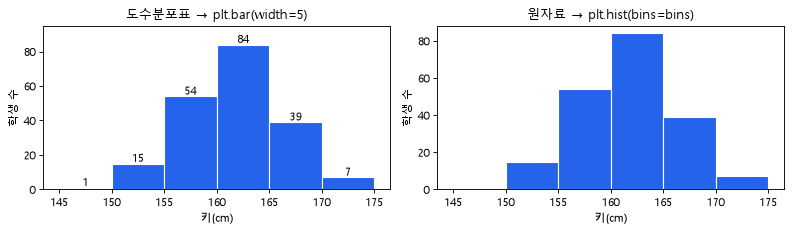

In [6]:
# 도수분포표 → 히스토그램: 표의 한 행 = 막대 1개 (강의 20 · 21쪽)
# 왜 · 히스토그램이 도수분포표를 그림으로 옮긴 것임을 확인하기 위해
counts, edges = np.histogram(height, bins=bins)  # 원자료에서 바로 구간별 개수
print("np.histogram 도수:", counts.tolist())     # 마지막 구간은 175 포함
print("도수분포표와 같은가:", (counts == freq["도수"].to_numpy()).all())  # 같은 표


fig, axes = plt.subplots(1, 2, figsize=(10, 3))     # 표로 그리기 vs 원자료로 그리기
# 막대 폭 = 구간 폭
axes[0].bar(freq["계급값"], freq["도수"], width=5, color="#2563eb", edgecolor="white")
for x, n in zip(freq["계급값"], freq["도수"]):      # 막대 위 숫자
    axes[0].text(x, n + 1, n, ha="center")          # 도수 표시
axes[0].set_title("도수분포표 → plt.bar(width=5)")  # 표에서 그림
axes[0].set_ylim(0, 95)                             # 막대 위 숫자 자리
axes[1].hist(height, bins=bins, color="#2563eb", edgecolor="white")  # 원자료에서 그림
axes[1].set_title("원자료 → plt.hist(bins=bins)")   # 같은 모양
for ax in axes:                                     # 두 칸 공통
    ax.set_xlabel("키(cm)")                         # 가로 = 구간
    ax.set_ylabel("학생 수")                        # 세로 = 도수
plt.tight_layout()                                  # 칸 간격 정리
plt.show()                                          # 그림 출력

**결과** · 예측 정답은 같음 — `[1, 15, 54, 84, 39, 7]`

- `np.histogram 도수: [1, 15, 54, 84, 39, 7]` — 마지막 구간만 오른쪽 끝값까지 포함 (강의 표의 '포함')
- `도수분포표와 같은가: True` — 표 = 그림의 숫자판
- 그림 · 두 칸이 같은 모양, 160~165 막대가 가장 높고 양쪽으로 낮아짐

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>도수분포표</td><td>숫자 → 표</td><td>정확한 개수 · 비율이 필요할 때</td></tr>
<tr><td>히스토그램</td><td>표 → 그림</td><td>모양 · 꼬리를 한눈에 볼 때</td></tr>
<tr><td><code>plt.bar(width=5)</code></td><td>이미 센 표로 그림</td><td>집계된 자료만 있을 때</td></tr>
<tr><td><code>plt.hist(bins=bins)</code></td><td>원자료를 직접 세서 그림</td><td>원자료가 있을 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `bar`로 그릴 때 `width`를 구간 폭과 같게 해야 막대가 붙음
> - `np.histogram`은 마지막 구간만 오른쪽 끝을 포함

> ✅ **한 줄 정리** · 도수분포표의 한 행이 히스토그램의 막대 하나이므로, 구간과 도수만 있으면 bar로, 원자료가 있으면 hist로 같은 그림을 그린다.

**딥러닝 코드에서는**

- 가중치 · 기울기 분포를 `plt.hist`로 확인 (기울기 소실 점검)
- TensorBoard의 histogram 탭이 같은 그림

---
## 3. 히스토그램

> **이 장의 흐름**
>
> - 결제액처럼 오른쪽 꼬리가 긴 데이터에서 평균과 중앙값이 얼마나 다른지 봄
> - 그다음 같은 키 데이터의 bins를 바꿔 '카메라 줌' 효과를 확인

<img src="images/st1_hist.png" alt="히스토그램에서 읽을 4가지" width="740">

**파이프라인 위치** · ② 요약 → ③ 해석

### 3-1. `A` 평균 착시와 분포 모양 · `ax.axvline` · `np.median` <sub>PDF 23 ~ 30쪽</sub>

> 🎯 **'고객 평균 결제액'만 보고 판단하면 왜 틀리는가?**

💡 **쉽게 말하면**

- 몇 명이 아주 많이 쓰면 **평균이 꼬리 쪽으로 끌려감**.
- 히스토그램을 보면 대부분은 평균보다 훨씬 적게 쓴 것이 보임.

**실행 흐름**

1. 결제액 200명 (보통 고객 190명 + 큰손 10명)
2. 평균 · 중앙값 · 평균 미만 비율
3. 히스토그램에 두 선

**먼저 예측** · 평균보다 적게 쓴 고객은 절반쯤일까, 훨씬 많을까? — 답은 코드 실행 결과 아래에

평균 57.0만 원 | 중앙값 25.0만 원
평균보다 적게 쓴 고객: 91%


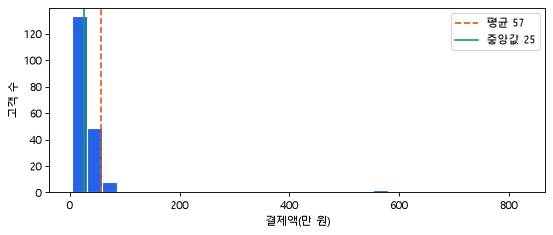

In [7]:
# 백화점 고객 200명 결제액 (강의 27 · 28쪽): 대부분 작고 일부만 매우 큼
# 왜 · 한쪽으로 꼬리가 긴 분포에서 평균이 끌려가는 상황을 재현하기 위해
spend = np.r_[rng.lognormal(np.log(25), 0.5, 190), rng.uniform(300, 900, 10)].round()  # 만 원
print(f"평균 {spend.mean():.1f}만 원 | 중앙값 {np.median(spend):.1f}만 원")  # 평균이 훨씬 큼
print(f"평균보다 적게 쓴 고객: {(spend < spend.mean()).mean():.0%}")         # '평균 고객'은 소수


fig, ax = plt.subplots(figsize=(8, 3))                       # 한 칸
ax.hist(spend, bins=30, color="#2563eb", edgecolor="white")  # 분포 모양
# 꼬리에 끌려감
ax.axvline(spend.mean(), color="#ea580c", ls="--", label=f"평균 {spend.mean():.0f}")
ax.axvline(np.median(spend), color="#16a34a", label=f"중앙값 {np.median(spend):.0f}")  # 가운데 고객
ax.set_xlabel("결제액(만 원)")                               # 가로 = 값 구간
ax.set_ylabel("고객 수")                                     # 세로 = 개수
ax.legend()                                                  # 선 이름
plt.show()                                                   # 그림 출력

**결과** · 예측 정답은 훨씬 많음 — 91%

- `평균 57.0만 원 | 중앙값 25.0만 원` — 평균이 중앙값의 두 배 넘음
- `평균보다 적게 쓴 고객: 91%` — '평균 고객'은 거의 없음 (강의 28쪽 '부자 고객이 많다' 착각)
- 그림 · 왼쪽에 몰리고 오른쪽으로 긴 꼬리 · 주황 평균선이 초록 중앙값선보다 오른쪽

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>대칭 분포</td><td>평균 ≈ 중앙값</td><td>평균으로 대표해도 됨</td></tr>
<tr><td>오른쪽 꼬리 (양의 왜도)</td><td>평균 &gt; 중앙값</td><td>소득 · 결제액 · 대기시간 → 중앙값</td></tr>
<tr><td>봉우리 2개</td><td>두 집단이 섞임</td><td>집단을 나눠서 봄</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 보고서의 평균 하나만 믿지 말고 분포를 먼저 그리기
> - 큰 값을 바로 지우지 말 것 · VIP처럼 진짜일 수 있음 (7장)

> ✅ **한 줄 정리** · 히스토그램은 몰린 곳 · 모양(대칭 · 치우침) · 꼬리 · 봉우리를 보여 주며, 꼬리가 긴 분포에서는 평균이 중앙값보다 꼬리 쪽으로 끌려간다.

**딥러닝 코드에서는**

- 회귀 타깃이 꼬리가 길면 로그 변환 뒤 학습
- 손실 값 분포에서 꼬리 쪽 샘플 = 어려운 샘플 · 라벨 오류 후보

### 3-2. `B` bins 크기 · 카메라 줌 · `ax.hist(bins=)` <sub>PDF 31 ~ 34쪽</sub>

> 🎯 **같은 데이터에서 bins만 바꾸면 히스토그램은 어떻게 달라지는가?**

💡 **쉽게 말하면**

- bins가 너무 적으면 **줌 아웃** · 디테일이 사라짐.
- 너무 많으면 **줌 인** · 들쭉날쭉한 잡음만 보임.

**실행 흐름**

1. 같은 키 200명
2. bins 3 · 6 · 40으로 세 칸
3. 빈 구간 · 가장 큰 막대 비교

**먼저 예측** · bins=40이면 빈 구간이 생길까? — 답은 코드 실행 결과 아래에

bins= 3 | 막대 3개 | 빈 구간 0개 | 가장 큰 막대 113명
bins= 6 | 막대 6개 | 빈 구간 0개 | 가장 큰 막대 65명
bins=40 | 막대 40개 | 빈 구간 1개 | 가장 큰 막대 12명


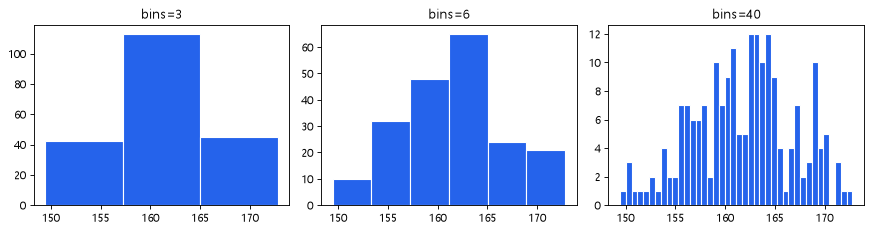

In [8]:
# 같은 키 200명, bins만 3 · 6 · 40으로 (강의 31쪽 '카메라 줌')
# 왜 · 구간 수에 따라 같은 데이터의 모양이 다르게 보인다는 것을 비교하기 위해
fig, axes = plt.subplots(1, 3, figsize=(11, 3))                            # 가로 3칸
for ax, b in zip(axes, [3, 6, 40]):                                        # 구간 개수만 바꿈
    n, _, _ = ax.hist(height, bins=b, color="#2563eb", edgecolor="white")  # n = 구간별 개수
    ax.set_title(f"bins={b}")                                              # 칸 제목에 bins
    # 줌 비교
    print(f"bins={b:>2} | 막대 {b}개 | 빈 구간 {(n == 0).sum()}개 | 가장 큰 막대 {int(n.max())}명")
plt.tight_layout()                                                         # 칸 간격 정리
plt.show()                                                                 # 그림 출력

**결과** · 예측 정답은 생김 — 1개 · 막대도 12명 이하로 들쭉날쭉

- `bins= 3 | 막대 3개 | 빈 구간 0개 | 가장 큰 막대 113명` — 봉우리 위치가 흐릿함
- `bins= 6 | 막대 6개 | 빈 구간 0개 | 가장 큰 막대 65명` — 강의 표와 비슷한 모양
- `bins=40 | 막대 40개 | 빈 구간 1개 | 가장 큰 막대 12명` — 잡음 때문에 봉우리가 여러 개처럼 보임

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>bins 적게</td><td>큰 흐름만 · 디테일 소실</td><td>발표용 요약</td></tr>
<tr><td>bins 적당히</td><td>모양과 디테일이 함께</td><td>기본 (구간 폭을 의미 있게: 5cm · 1만 원)</td></tr>
<tr><td>bins 많이</td><td>잡음 · 빈 구간</td><td>데이터가 아주 많을 때만</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - bins를 바꿔 원하는 모양을 만드는 것은 그래프 속이기
> - 막대 높이는 bins에 따라 달라지므로 다른 bins끼리 높이를 비교하지 않기

> ✅ **한 줄 정리** · bins는 카메라 줌과 같아서 너무 적으면 디테일이 사라지고 너무 많으면 잡음만 보이므로, 의미 있는 구간 폭으로 정한다.

**딥러닝 코드에서는**

- `plt.hist(..., bins=50)` 같은 숫자는 데이터 양을 보고 정함
- bins를 정한 뒤에는 바꾸지 않고 학습 전 · 후 분포를 비교

---
## 4. 대표값과 퍼짐 (보강)

> **이 장의 흐름**
>
> - 강의가 '진행 예정'으로 남긴 대표값 3가지를 계산하고 극단값의 영향을 비교
> - 그다음 분산 · 표준편차를 손으로 계산하고, 다섯 숫자 요약 · IQR로 넘어감

<img src="images/st1_spread.png" alt="중심(평균 · 중앙값)과 퍼짐(표준편차 · IQR)" width="989">

**파이프라인 위치** · ② 요약 (숫자로)

### 4-1. `A` 평균 · 중앙값 · 최빈값 · `mean` · `median` · `mode` <sub>PDF 3 · 4 · 26 · 40쪽 (보강)</sub>

> 🎯 **평균 · 중앙값 · 최빈값은 각각 무엇이고, 극단값 하나에 어떻게 반응하는가?**

💡 **쉽게 말하면**

- 평균 = 다 더해 나눈 값 · 중앙값 = 줄 세웠을 때 가운데 · 최빈값 = 가장 많이 나온 값.
- 대표 연봉 하나가 들어오면 평균은 크게 뛰지만 중앙값은 거의 그대로.

**실행 흐름**

1. 점수 10개의 세 대표값
2. 정렬해서 중앙값 확인
3. 연봉 5명 + 대표 1명 → 평균 · 중앙값 변화

**먼저 예측** · 연봉 5억이 들어오면 평균과 중앙값은 각각 얼마나 움직일까? — 답은 코드 실행 결과 아래에

In [9]:
# 대표값 3가지: 평균 · 중앙값 · 최빈값 (강의 3 · 4쪽의 시험 점수)
# 왜 · 세 대표값이 같은 데이터에서 어떻게 다른지 나란히 보기 위해
score = pd.Series([78, 68, 88, 98, 78, 85, 72, 78, 90, 65])  # 10명
# 세 값 비교
print("평균:", score.mean(), "| 중앙값:", score.median(), "| 최빈값:", score.mode().tolist())
print("정렬:", sorted(score))                                # 중앙값 = 가운데 두 값(78, 78)의 평균


# 극단값 하나가 들어오면: 연봉(만 원) 5명 + 대표 1명
# 왜 · 극단값에는 평균보다 중앙값이 덜 흔들린다는 것을 확인하기 위해
pay_year = pd.Series([3000, 3200, 3400, 3500, 3600])                    # 직원 5명
with_ceo = pd.concat([pay_year, pd.Series([50000])])                    # 대표 연봉 5억 추가
for name, s in [("직원 5명", pay_year), ("+ 대표", with_ceo)]:          # 추가 전 · 후
    print(f"{name} | 평균 {s.mean():7.1f} | 중앙값 {s.median():6.1f}")  # 평균만 크게 움직임

평균: 80.0 | 중앙값: 78.0 | 최빈값: [78]
정렬: [65, 68, 72, 78, 78, 78, 85, 88, 90, 98]
직원 5명 | 평균  3340.0 | 중앙값 3400.0
+ 대표 | 평균 11116.7 | 중앙값 3450.0


**결과** · 예측 정답은 평균 3340 → 11116.7 (3배 넘게) · 중앙값 3400 → 3450 (50만 원)

- `평균: 80.0 | 중앙값: 78.0 | 최빈값: [78]` — 세 값이 비슷 → 치우침이 작음
- `정렬: [65, 68, 72, 78, 78, 78, 85, 88, 90, 98]` — 10개라 5 · 6번째(78, 78)의 평균이 중앙값
- `직원 5명 | 평균  3340.0 | 중앙값 3400.0` — 극단값 없음
- `+ 대표 | 평균 11116.7 | 중앙값 3450.0` — 평균은 대표 한 명에 끌려감 · 중앙값은 그대로

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>평균 <code>mean()</code></td><td>모든 값을 씀 · 극단값에 약함</td><td>대칭 분포 · 합계와 연결될 때</td></tr>
<tr><td>중앙값 <code>median()</code></td><td>가운데 값 · 극단값에 강함</td><td>소득 · 집값 · 대기시간</td></tr>
<tr><td>최빈값 <code>mode()</code></td><td>가장 흔한 값 · 여러 개일 수 있음</td><td>범주형 · 가장 많이 팔린 메뉴</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `mode()`는 리스트(Series)로 나옴 · 최빈값이 여럿이면 모두
> - 짝수 개의 중앙값은 가운데 두 값의 평균

> ✅ **한 줄 정리** · 평균은 모든 값을 쓰지만 극단값에 끌려가고, 중앙값은 가운데 값이라 극단값에 강하며, 최빈값은 범주형에도 쓸 수 있다.

**딥러닝 코드에서는**

- 회귀 손실 MSE의 최적 예측 = 평균 · MAE의 최적 예측 = 중앙값
- 기준선(baseline) 모델 = '항상 평균(또는 최빈 클래스)으로 예측'

### 4-2. `A` 분산 · 표준편차 · `np.var` · `np.std` · `ddof` <sub>PDF 26 · 68 · 79쪽 (보강)</sub>

> 🎯 **평균이 같은 두 반의 차이를 숫자로 나타내려면 무엇을 계산하는가?**

💡 **쉽게 말하면**

- **편차** = 값 - 평균 · 그대로 더하면 0이라 제곱해서 평균 = 분산.
- 분산은 단위가 제곱이라 제곱근을 씌운 것이 표준편차 (원래 단위).

**실행 흐름**

1. 반 A(σ=3) · 반 B(σ=15) 30명씩
2. 작은 예 5개로 편차 → 제곱 → 평균
3. ÷n과 ÷(n-1) 비교

**먼저 예측** · 편차 `[-5, -1, 0, 1, 5]`의 합과, 분산(÷n)은? — 답은 코드 실행 결과 아래에

In [10]:
# 같은 평균 75점, 다른 퍼짐 (강의 68 · 79쪽: 반 A σ=3 · 반 B σ=15)
# 왜 · 평균만으로는 퍼짐을 알 수 없어 분산 · 표준편차가 필요하다는 것을 보이기 위해
class_a = rng.normal(75, 3, 30).round(1)                # 고르게 모인 반
class_b = rng.normal(75, 15, 30).round(1)               # 넓게 퍼진 반
for name, s in [("반 A", class_a), ("반 B", class_b)]:  # 두 반
    # 평균은 비슷 · 퍼짐은 다름
    print(f"{name} | 평균 {s.mean():.2f} | 표준편차 {s.std(ddof=1):.2f}")


# 분산을 손으로: 편차 → 제곱 → 평균 → 제곱근
# 왜 · 공식 대신 계산 순서로 분산 · 표준편차의 뜻을 이해하기 위해
x = np.array([70, 74, 75, 76, 80])                             # 작은 예 5개
dev = x - x.mean()                                             # 편차 = 값 - 평균
print("편차:", dev.tolist(), "| 합:", dev.sum())               # 편차의 합은 항상 0
print("분산(÷n):", (dev ** 2).mean(), "| np.var:", np.var(x))  # 제곱의 평균
# 표본 분산
print("분산(÷n-1):", (dev ** 2).sum() / (len(x) - 1), "| pandas var:", pd.Series(x).var())
# 단위가 원래대로
print("표준편차:", round(np.sqrt((dev ** 2).mean()), 3), "| np.std:", round(np.std(x), 3))

반 A | 평균 75.12 | 표준편차 2.93
반 B | 평균 75.94 | 표준편차 14.49
편차: [-5.0, -1.0, 0.0, 1.0, 5.0] | 합: 0.0
분산(÷n): 10.4 | np.var: 10.4
분산(÷n-1): 13.0 | pandas var: 13.0
표준편차: 3.225 | np.std: 3.225


**결과** · 예측 정답은 합 0 · 분산 10.4 (= 52 ÷ 5)

- `반 A | 평균 75.12 | 표준편차 2.93` — 평균 75 근처에 촘촘
- `반 B | 평균 75.94 | 표준편차 14.49` — 평균은 비슷하지만 다섯 배 가까이 퍼짐
- `편차: [-5.0, -1.0, 0.0, 1.0, 5.0] | 합: 0.0` — 편차 합은 항상 0 → 제곱이 필요
- `분산(÷n): 10.4 | np.var: 10.4` — NumPy 기본 = 모집단 분산 (52 ÷ 5 = 10.4)
- `분산(÷n-1): 13.0 | pandas var: 13.0` — pandas 기본 = 표본 분산 (52 ÷ 4 = 13.0)
- `표준편차: 3.225 | np.std: 3.225` — √10.4 · 점수와 같은 단위

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>분산</td><td>편차 제곱의 평균 · 단위²</td><td>계산 중간값 · 수식</td></tr>
<tr><td>표준편차</td><td>분산의 제곱근 · 원래 단위</td><td>보고 · 정규화</td></tr>
<tr><td><code>np.std(x)</code> (ddof=0)</td><td>÷n</td><td>가진 데이터 전체가 대상일 때</td></tr>
<tr><td><code>Series.std()</code> (ddof=1)</td><td>÷(n-1)</td><td>표본으로 전체를 추정할 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - NumPy와 pandas의 기본 ddof가 달라 값이 조금 다름 · 비교할 땐 ddof를 맞추기
> - 표준편차도 평균처럼 극단값에 약함 (7-2)

> ✅ **한 줄 정리** · 분산은 편차 제곱의 평균, 표준편차는 그 제곱근이며, NumPy는 ÷n · pandas는 ÷(n-1)이 기본이라 ddof를 확인한다.

**딥러닝 코드에서는**

- 표준화 `(x - mean) / std` · 이미지 정규화 `Normalize(mean, std)`
- BatchNorm은 배치마다 평균 · 분산을 계산해 같은 일을 함

### 4-3. `A` 다섯 숫자 요약 · IQR · `quantile` · `describe` <sub>PDF 69 · 72 · 73 · 83쪽</sub>

> 🎯 **사분위수와 IQR은 무엇이고, 이상점 후보 기준은 어떻게 정하는가?**

💡 **쉽게 말하면**

- 줄 세워서 **25% · 50% · 75% 지점**이 Q1 · 중앙값 · Q3.
- IQR = Q3 - Q1 = 가운데 50%의 폭 · 그 1.5배 밖이 이상점 후보.

**실행 흐름**

1. 반 B의 Q1 · Q2 · Q3
2. IQR · fence 계산
3. `describe()`로 한 번에

**먼저 예측** · 반 B 30명 중 fence 밖에 있는 학생이 있을까? — 답은 코드 실행 결과 아래에

In [11]:
# 다섯 숫자 요약 + IQR (강의 69 · 83쪽) — 반 B 30명
# 왜 · 박스플롯을 읽기 전에 다섯 숫자와 IQR을 직접 구하기 위해
s = pd.Series(class_b)                      # 4-2의 넓게 퍼진 반
q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])  # 하위 25% · 50% · 75% 지점
iqr = q3 - q1                               # 가운데 50%의 폭
# 다섯 숫자
print(f"최솟값 {s.min()} | Q1 {q1:.2f} | 중앙값 {q2:.2f} | Q3 {q3:.2f} | 최댓값 {s.max()}")
print(f"IQR {iqr:.2f} | fence {q1 - 1.5 * iqr:.2f} ~ {q3 + 1.5 * iqr:.2f}")  # 이상점 후보 기준선


# describe(): 개수 · 평균 · 표준편차 · 다섯 숫자를 한 번에
# 왜 · 손으로 구한 값과 pandas 요약이 같은지 확인하기 위해
print(s.describe().round(2).to_dict())  # 표 요약 한 줄

최솟값 49.7 | Q1 64.75 | 중앙값 76.85 | Q3 85.85 | 최댓값 110.9
IQR 21.10 | fence 33.10 ~ 117.50
{'count': 30.0, 'mean': 75.94, 'std': 14.49, 'min': 49.7, '25%': 64.75, '50%': 76.85, '75%': 85.85, 'max': 110.9}


**결과** · 예측 정답은 없음 — 최솟값 49.7 · 최댓값 110.9가 모두 fence(33.10 ~ 117.50) 안

- `최솟값 49.7 | Q1 64.75 | 중앙값 76.85 | Q3 85.85 | 최댓값 110.9` — 다섯 숫자 요약
- `IQR 21.10 | fence 33.10 ~ 117.50` — 85.85 - 64.75 = 21.10 · Q1 - 31.65 · Q3 + 31.65
- 한 줄 요약 `describe()` · 개수 30 · 평균 75.94 · 표준편차 14.49 · 사분위수까지

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>표준편차</td><td>평균 기준 퍼짐 · 극단값에 약함</td><td>대칭 분포</td></tr>
<tr><td>IQR</td><td>가운데 50% 폭 · 극단값에 강함</td><td>치우친 분포 · 이상점 기준</td></tr>
<tr><td><code>describe()</code></td><td>개수 · 평균 · 표준편차 · 다섯 숫자</td><td>데이터를 받자마자 첫 확인</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - fence 밖 = '삭제 대상'이 아니라 '확인할 후보' (강의 73쪽)
> - 사분위수 계산 방법은 라이브러리마다 조금 다름 · 표본이 작을수록 차이

> ✅ **한 줄 정리** · 다섯 숫자 요약은 최솟값 · Q1 · 중앙값 · Q3 · 최댓값이고, IQR = Q3 - Q1의 1.5배 밖을 이상점 후보로 표시한다.

**딥러닝 코드에서는**

- `df.describe()`로 특성마다 범위 · 이상치를 먼저 확인
- RobustScaler = (x - 중앙값) / IQR · 이상치가 많은 특성의 정규화

---
## 5. 변수 유형별 차트 고르기

> **이 장의 흐름**
>
> - 강의의 차트 치트 1 · 2를 함수 하나로 옮김
> - 강의의 예시 질문들을 넣어 추천 그래프가 맞는지 확인

<img src="images/st1_cheat.png" alt="변수 개수 × 유형 → 그래프" width="763">

**파이프라인 위치** · ③ 해석 → ④ 전달

### 5-1. `A` 차트 치트 시트를 함수로 · `def` · `if · elif` <sub>PDF 44 ~ 51 · 125 ~ 131쪽</sub>

> 🎯 **'성별 vs 시험 점수'와 '광고비 vs 매출액'은 각각 어떤 그래프인가?**

💡 **쉽게 말하면**

- **변수 1개** → 분포 · 비율, **2개** → 관계, **3개 이상** → 색 · 크기를 더함.
- 그다음 범주인지 수치인지로 막대 · 히스토그램 · 박스 · 산점도를 가름.

**실행 흐름**

1. `pick_chart(kinds, time)` 정의
2. 강의 예시 질문 5개 넣기
3. 시간 축이 있는 질문

**먼저 예측** · '지역 × 월 × 매출'처럼 변수가 3개면? — 답은 코드 실행 결과 아래에

In [12]:
# 차트 고르기 = 변수 개수 + 데이터 유형 (강의 46 · 51 · 126 · 127쪽)
# 왜 · 그래프 선택 기준을 함수로 정리해 같은 규칙으로 고르기 위해
def pick_chart(kinds, time=False):               # kinds: 변수마다 "범주" 또는 "수치"
    if time:                                     # 시간 순서 + 수치
        return "선그래프"                        # 변화 · 추세
    if len(kinds) == 1:                          # 일변량
        # 범주 vs 수치
        one = "막대그래프 · 원그래프" if kinds[0] == "범주" else "히스토그램 · 박스플롯"
        return one                               # 분포 · 비율
    if len(kinds) == 2:                          # 이변량
        if kinds.count("범주") == 2:             # 범주 + 범주
            return "집단별 막대그래프"           # 묶은 막대
        return "집단별 박스플롯" if "범주" in kinds else "산점도"  # 범주 + 수치 vs 수치 + 수치
    return "히트맵 · 버블차트 (색 · 크기 추가)"  # 다변량


cases = [("결제수단 구성", ["범주"]), ("고객 대기시간 분포", ["수치"]),  # 일변량 2개
         ("성별 vs 시험 점수", ["범주", "수치"]), ("광고비 vs 매출액", ["수치", "수치"]),  # 이변량
         ("지역 x 월 x 매출", ["범주", "범주", "수치"])]                 # 다변량
for q, kinds in cases:                                                   # 질문마다
    print(f"{q} → {pick_chart(kinds)}")                                  # 추천 그래프
print("일별 매출 추이 →", pick_chart(["수치"], time=True))               # 시간 축이 있으면

결제수단 구성 → 막대그래프 · 원그래프
고객 대기시간 분포 → 히스토그램 · 박스플롯
성별 vs 시험 점수 → 집단별 박스플롯
광고비 vs 매출액 → 산점도
지역 x 월 x 매출 → 히트맵 · 버블차트 (색 · 크기 추가)
일별 매출 추이 → 선그래프


**결과** · 예측 정답은 히트맵 · 버블차트

- `결제수단 구성 → 막대그래프 · 원그래프` — 범주 1개
- `고객 대기시간 분포 → 히스토그램 · 박스플롯` — 수치 1개
- `성별 vs 시험 점수 → 집단별 박스플롯` — 범주 + 수치 (강의 49쪽)
- `광고비 vs 매출액 → 산점도` — 수치 + 수치
- `지역 x 월 x 매출 → 히트맵 · 버블차트 (색 · 크기 추가)` — 다변량 (강의 50쪽)
- `일별 매출 추이 → 선그래프` — 시간 순서 + 수치

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>일변량</td><td>분포 · 비율</td><td>막대 · 원 · 히스토그램 · 박스</td></tr>
<tr><td>이변량</td><td>관계 · 집단 비교</td><td>집단별 막대 · 박스 · 산점도 · 선</td></tr>
<tr><td>다변량</td><td>색 · 크기로 축을 하나 더</td><td>히트맵 · 버블차트</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 질문을 먼저 정하고 그래프를 고르기 · 그래프부터 고르면 엉뚱한 그림
> - 시간 순서가 있으면 수치 1개라도 선그래프

> ✅ **한 줄 정리** · 차트는 '변수 개수 + 데이터 유형'으로 고르며, 일변량은 분포 · 비율, 이변량은 관계, 다변량은 색 · 크기를 더한다.

**딥러닝 코드에서는**

- 학습 곡선 = 시간(epoch) + 수치 → 선 · 혼동 행렬 = 범주 × 범주 → 히트맵
- 임베딩 2차원 시각화 = 수치 + 수치 + 범주(색) → 색을 넣은 산점도

---
## 6. 막대그래프 · 원그래프

> **이 장의 흐름**
>
> - 결제수단 개수를 막대로 그리고 막대 위에 숫자를 붙임
> - 그다음 항목이 3개일 때와 8개일 때 원그래프 · 막대그래프를 비교

<img src="images/st1_barpie.png" alt="막대 = 길이 비교 · 원 = 전체 중 비율" width="776">

**파이프라인 위치** · ③ 해석 → ④ 전달

### 6-1. `A` 막대그래프 · 범주별 빈도 · `ax.bar_label` · `ax.set_ylim` <sub>PDF 52 ~ 59쪽</sub>

> 🎯 **카드 · 현금 결제가 각각 몇 건인지 한눈에 보이게 하려면?**

💡 **쉽게 말하면**

- 범주마다 **막대 높이 = 개수**.
- 막대 사이를 띄우고, 위에 숫자를 붙이면 바로 읽힘.

**실행 흐름**

1. 결제수단 100건 개수 · 비율
2. 막대 + 숫자 라벨
3. 세로축 0부터

**먼저 예측** · 카드 비율은? — 답은 코드 실행 결과 아래에

개수: {'카드': 70, '현금': 30} | 비율: {'카드': 0.7, '현금': 0.3}


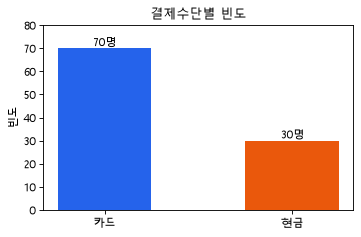

In [13]:
# 결제수단 100건: 막대그래프로 범주별 개수 · 비율 (강의 53 ~ 59쪽)
# 왜 · 범주형 변수는 막대로 개수와 비율을 함께 보여 주기 위해
method = pd.Series(["카드"] * 70 + ["현금"] * 30)                      # 범주형 1개
cnt = method.value_counts()                                            # 범주 → 개수
print("개수:", cnt.to_dict(), "| 비율:", (cnt / cnt.sum()).to_dict())  # 개수 · 비율


fig, ax = plt.subplots(figsize=(5, 3))                                         # 한 칸
bars = ax.bar(cnt.index, cnt.values, color=["#2563eb", "#ea580c"], width=0.5)  # 막대 사이 간격
ax.bar_label(bars, labels=[f"{v}명" for v in cnt.values])                      # 막대 위 숫자
ax.set_ylim(0, 80)                                                             # 세로축 0부터
ax.set_ylabel("빈도")                                                          # 세로 = 개수
ax.set_title("결제수단별 빈도")                                                # 무엇을 셌는지
plt.show()                                                                     # 그림 출력

**결과** · 예측 정답은 0.7 (70%)

- `개수: {'카드': 70, '현금': 30} | 비율: {'카드': 0.7, '현금': 0.3}` — 개수 ÷ 전체 = 비율
- 그림 · 막대 사이 간격 · 위에 '70명' · '30명' · 세로축 0 ~ 80

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>세로 막대</td><td>범주가 적고 이름이 짧을 때</td><td>결제수단 · 요일</td></tr>
<tr><td>가로 막대</td><td>범주가 많거나 이름이 길 때</td><td>메뉴 · 지역 순위</td></tr>
<tr><td>집단별 막대</td><td>범주 2개 (예: 성별 × 결제수단)</td><td>이변량 범주 비교</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 막대 사이는 반드시 띄우기 (붙이면 히스토그램처럼 보임)
> - 범주가 많으면 상위 몇 개만 · 필요한 항목만 (강의 58쪽)

> ✅ **한 줄 정리** · 막대그래프는 범주별 개수 · 비율을 막대 높이로 보여 주는 가장 직관적인 그래프이며, 세로축은 0부터 시작한다.

**딥러닝 코드에서는**

- 클래스별 샘플 수를 막대로 그려 불균형 확인
- 모델별 정확도 비교 · 막대 위에 숫자 라벨

### 6-2. `B` 원그래프 vs 막대그래프 · `ax.pie` · `autopct` · `ax.barh` <sub>PDF 60 ~ 66쪽</sub>

> 🎯 **항목이 8개인 비율을 원그래프로 그리면 무엇이 어려운가?**

💡 **쉽게 말하면**

- 원그래프는 **전체 중 비율**을 보이기 좋지만, 조각 크기 비교는 사람 눈이 약함.
- 항목이 많고 값이 비슷하면 막대가 훨씬 정확.

**실행 흐름**

1. 카드 50 · 현금 30 · 간편결제 20
2. 비슷한 값 8개
3. 원 3개 · 원 8개 · 막대 8개

**먼저 예측** · 8개 중 1등은 원그래프에서 바로 보일까? — 답은 코드 실행 결과 아래에

3개 합: 100 | 8개 합: 100 | 8개 중 1등: A


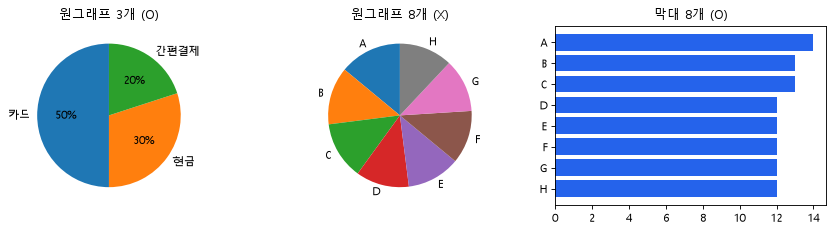

In [14]:
# 원그래프 vs 막대그래프: 3개일 때와 8개일 때 (강의 61 · 66쪽)
# 왜 · 항목이 많아지면 원그래프가 비교하기 어려워지는 것을 보이기 위해
share = pd.Series({"카드": 50, "현금": 30, "간편결제": 20})                 # 강의 61쪽 비율
many = pd.Series([14, 13, 13, 12, 12, 12, 12, 12], index=list("ABCDEFGH"))  # 비슷한 8개
print("3개 합:", share.sum(), "| 8개 합:", many.sum(), "| 8개 중 1등:", many.idxmax())  # 합 100%


fig, axes = plt.subplots(1, 3, figsize=(11, 3))                     # 가로 3칸
axes[0].pie(share, labels=share.index, autopct="%d%%", startangle=90)  # 3개 → 비율이 잘 보임
axes[0].set_title("원그래프 3개 (O)")                               # 4 ~ 5개 이하
axes[1].pie(many, labels=many.index, startangle=90)                 # 8개 → 조각 크기 비교가 어려움
axes[1].set_title("원그래프 8개 (X)")                               # 각도 착시
axes[2].barh(many.index[::-1], many.values[::-1], color="#2563eb")  # 같은 8개를 막대로
axes[2].set_title("막대 8개 (O)")                                   # 길이 비교는 쉬움
plt.tight_layout()                                                  # 칸 간격 정리
plt.show()                                                          # 그림 출력

**결과** · 예측 정답은 잘 안 보임 — A(14)와 B · C(13)의 차이는 막대에서만 보임

- `3개 합: 100 | 8개 합: 100 | 8개 중 1등: A` — 둘 다 합 100%
- 그림 · 원 3개는 비율이 잘 보이고, 원 8개는 조각이 비슷해 순위를 알기 어려우며, 막대 8개는 A가 가장 긺

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>원그래프 <code>pie</code></td><td>전체 대비 비중 · 4 ~ 5개 이하</td><td>구성비 · 점유율</td></tr>
<tr><td>막대그래프 <code>bar · barh</code></td><td>길이 비교 · 개수 제한 없음</td><td>순위 · 차이 비교</td></tr>
<tr><td>100% 누적 막대</td><td>여러 집단의 구성비를 나란히</td><td>연도별 점유율</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 원그래프는 항목 4 ~ 5개 이하일 때만 (강의 66쪽)
> - 각도 착시 · 3D 원그래프는 쓰지 않기

> ✅ **한 줄 정리** · 원그래프는 항목이 적을 때 전체 중 비중을 보여 주고, 항목이 많거나 값이 비슷하면 막대그래프가 더 정확하다.

**딥러닝 코드에서는**

- 데이터셋 클래스 구성 발표는 막대가 기본
- 통계 파일별 2 문제 39에서 파이 vs 가로 막대를 다시 비교

---
## 7. 박스플롯

> **이 장의 흐름**
>
> - 4장의 두 반을 박스플롯으로 그려 박스 길이(IQR)를 비교
> - 그다음 극단값 후보를 넣기 전 · 후의 평균 · 중앙값 · 표준편차 · 박스를 비교

<img src="images/st1_box.png" alt="박스플롯 부위별 뜻" width="700">

**파이프라인 위치** · ② 요약 → ③ 해석

### 7-1. `A` 같은 평균, 다른 퍼짐 · `ax.boxplot` · `np.percentile` <sub>PDF 67 ~ 80쪽</sub>

> 🎯 **평균 75점인 두 반의 박스플롯은 어떻게 다른가?**

💡 **쉽게 말하면**

- 상자 = 가운데 50% (Q1 ~ Q3) · 안의 선 = 중앙값 · 수염 = fence 안의 끝값.
- 상자가 짧으면 고르게 모임, 길면 들쭉날쭉.

**실행 흐름**

1. `five(s)` 함수 (중앙값 · IQR · 후보)
2. 두 반 요약
3. 박스플롯 두 개

**먼저 예측** · 반 B의 IQR은 반 A의 몇 배쯤일까? — 답은 코드 실행 결과 아래에

반 A | 중앙값 75.2 | IQR 3.7 | 이상점 후보 []
반 B | 중앙값 76.8 | IQR 21.1 | 이상점 후보 []


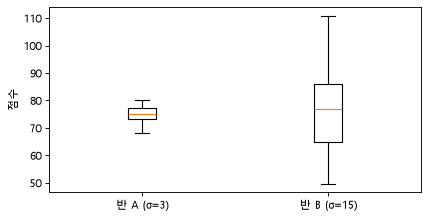

In [15]:
# 반 A vs 반 B 박스플롯 (강의 68 · 75 · 80쪽) — 4-2의 두 반
# 왜 · 평균이 같은 두 반의 퍼짐 차이를 한눈에 비교하기 위해
def five(s):                                                    # 다섯 숫자 + fence
    q1, q3 = np.percentile(s, [25, 75])                         # 사분위수
    iqr = q3 - q1                                               # 박스 길이
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr                     # fence
    out = s[(s < lo) | (s > hi)]                                # fence 밖 = 이상점 후보
    return round(np.median(s), 1), round(iqr, 1), out.tolist()  # 중앙값 · IQR · 후보


for name, s in [("반 A", class_a), ("반 B", class_b)]:               # 두 반
    med, iqr, out = five(s)                                          # 요약
    print(f"{name} | 중앙값 {med} | IQR {iqr} | 이상점 후보 {out}")  # 박스 길이 비교


fig, ax = plt.subplots(figsize=(6, 3))                                     # 한 칸
ax.boxplot([class_a, class_b], tick_labels=["반 A (σ=3)", "반 B (σ=15)"])  # 상자 = Q1 ~ Q3
ax.set_ylabel("점수")                                                      # 세로 = 값
plt.show()                                                                 # 그림 출력

**결과** · 예측 정답은 약 5.7배 (3.7 → 21.1)

- `반 A | 중앙값 75.2 | IQR 3.7 | 이상점 후보 []` — 박스가 짧음 · 안정적
- `반 B | 중앙값 76.8 | IQR 21.1 | 이상점 후보 []` — 박스 · 수염 모두 긺
- 그림 · 중앙값 높이는 비슷하고 반 B의 상자가 훨씬 길며, 두 반 모두 점(이상점 후보)이 없음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>평균 막대</td><td>중심 하나만</td><td>숫자 비교만 할 때</td></tr>
<tr><td>박스플롯</td><td>중앙값 · IQR · 수염 · 후보</td><td>집단 간 분포 비교</td></tr>
<tr><td>히스토그램</td><td>모양 전체 · 봉우리</td><td>집단 하나를 자세히</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - Tukey 박스플롯의 수염은 실제 최솟값 · 최댓값이 아닐 수 있음 (강의 69쪽)
> - 표본이 적으면 박스가 왜곡될 수 있음

> ✅ **한 줄 정리** · 박스플롯은 중앙값 · IQR · 수염 · 이상점 후보를 한 번에 보여 주므로, 평균이 같아도 퍼짐이 다른 집단을 바로 구분한다.

**딥러닝 코드에서는**

- 모델을 여러 번 학습한 점수(seed별)를 박스플롯으로 비교
- 특성별 박스플롯으로 스케일 · 이상치를 확인

### 7-2. `A` 극단값 후보를 넣기 전 · 후 · `np.r_` <sub>PDF 81 ~ 84쪽</sub>

> 🎯 **극단값 후보가 들어오면 평균 · 중앙값 · 표준편차 · 박스 중 무엇이 크게 변하는가?**

💡 **쉽게 말하면**

- 양쪽에 하나씩 들어오면 평균은 우연히 그대로일 수 있지만 **표준편차는 크게 뜀**.
- 한쪽에만 들어오면 평균도 끌려감 · 박스(IQR)와 중앙값은 거의 그대로.

**실행 흐름**

1. 점수 40개
2. 양쪽 추가(100 · 30) · 한쪽 추가(100 · 98)
3. 세 경우 요약 · 박스플롯

**먼저 예측** · 100과 30을 함께 넣으면 평균은 얼마나 변할까? — 답은 코드 실행 결과 아래에

기본 | 평균 64.95 | 중앙값 65.45 | 표준편차 2.83
양쪽 추가 | 평균 64.95 | 중앙값 65.45 | 표준편차 8.12
한쪽 추가 | 평균 66.57 | 중앙값 65.70 | 표준편차 7.76
fence 59.9 ~ 70.6


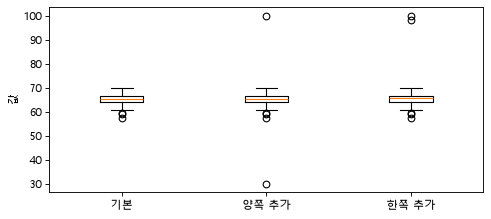

In [16]:
# 극단값 후보를 넣기 전 · 후 (강의 81 · 82쪽): 양쪽에 하나씩 vs 한쪽에만
# 왜 · 극단값 위치에 따라 박스플롯이 어떻게 바뀌는지 확인하기 위해
base = rng.normal(65, 3, 40).round(1)  # 점수 40개
both = np.r_[base, [100, 30]]          # 아주 큰 값 + 아주 작은 값
one = np.r_[base, [100, 98]]           # 큰 값만 두 개
for name, s in [("기본", base), ("양쪽 추가", both), ("한쪽 추가", one)]:  # 세 경우
    # 비교
    print(f"{name} | 평균 {s.mean():.2f} | 중앙값 {np.median(s):.2f} | 표준편차 {s.std():.2f}")


q1, q3 = np.percentile(both, [25, 75])                                   # 양쪽 추가 후 사분위수
print(f"fence {q1 - 1.5 * (q3 - q1):.1f} ~ {q3 + 1.5 * (q3 - q1):.1f}")  # 이 밖이 점으로 표시


fig, ax = plt.subplots(figsize=(7, 3))                                         # 한 칸
ax.boxplot([base, both, one], tick_labels=["기본", "양쪽 추가", "한쪽 추가"])  # 상자는 거의 그대로
ax.set_ylabel("값")                                                            # 세로 = 값
plt.show()                                                                     # 그림 출력

**결과** · 예측 정답은 거의 그대로(64.95) — 대신 표준편차가 2.83 → 8.12로 세 배 가까이

- `기본 | 평균 64.95 | 중앙값 65.45 | 표준편차 2.83` — 기준
- `양쪽 추가 | 평균 64.95 | 중앙값 65.45 | 표준편차 8.12` — 평균은 서로 상쇄 · 퍼짐만 커짐
- `한쪽 추가 | 평균 66.57 | 중앙값 65.70 | 표준편차 7.76` — 평균이 위로 끌려감 · 중앙값은 0.25만 움직임
- `fence 59.9 ~ 70.6` — 추가한 두 값은 fence 밖 → 점으로 표시

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>평균 · 표준편차</td><td>극단값에 약함</td><td>극단값을 확인 · 처리한 뒤</td></tr>
<tr><td>중앙값 · IQR</td><td>극단값에 강함</td><td>극단값이 있을 수 있는 원자료</td></tr>
<tr><td>fence 밖 점</td><td>자동 삭제 대상 아님</td><td>원인을 확인할 목록</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 평균이 그대로라고 극단값이 없다고 판단하지 않기 · 표준편차와 그림을 함께
> - 기본 데이터에도 fence 밖 점이 있을 수 있음 · 정상 범위인지 확인

> ✅ **한 줄 정리** · 극단값 후보는 평균과 표준편차를 크게 움직일 수 있지만 중앙값과 IQR은 거의 그대로이므로, 박스플롯으로 함께 확인한다.

**딥러닝 코드에서는**

- 이상치가 많은 특성은 평균 · 표준편차 대신 중앙값 · IQR로 정규화
- 손실이 튀는 배치 = 극단값 샘플 확인 (라벨 오류 · 깨진 이미지)

---
## 8. 산점도 · 선그래프 · 히트맵

> **이 장의 흐름**
>
> - 광고비 · 매출 산점도에서 일반 패턴과 예외점을 보고 상관과 인과를 구분
> - 그다음 카페 일매출 선그래프로 주말 효과를, 지역 × 월 히트맵으로 계절성을 읽음

<img src="images/st1_relation.png" alt="산점도 · 선그래프 · 히트맵이 답하는 질문" width="988">

**파이프라인 위치** · ③ 해석 → ④ 전달

### 8-1. `A` 산점도 · 상관 ≠ 인과 · `ax.scatter` · `np.corrcoef` <sub>PDF 85 ~ 98쪽</sub>

> 🎯 **광고비와 매출이 같이 늘었다면 광고 때문이라고 할 수 있는가?**

💡 **쉽게 말하면**

- 점 1개 = 1개월 · 오른쪽 위로 올라가면 **양의 상관**.
- 같이 움직인다는 것(상관)과 원인(인과)은 다름 · 점 하나가 상관계수를 크게 바꾸기도 함.

**실행 흐름**

1. 광고비 25개월 · 매출 ≈ 2배 + 잡음
2. 상관계수 (예외 없음 · 포함)
3. 산점도 + 예외점 강조

**먼저 예측** · 광고비 180 · 매출 100인 달 하나를 넣으면 상관계수는? — 답은 코드 실행 결과 아래에

상관계수 | 예외 없음 0.988 | 예외 포함 0.847


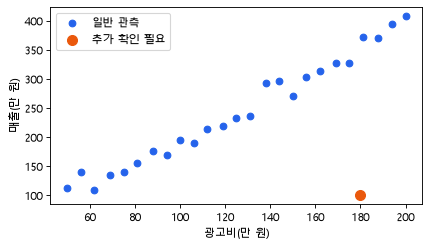

In [17]:
# 광고비(만 원) vs 매출(만 원) 25개월 + 예외 1개월 (강의 89 · 96쪽)
# 왜 · 두 수치 변수의 관계와 예외 점을 산점도로 보기 위해
ad = np.linspace(50, 200, 25).round()                        # 광고비 50 ~ 200
sales = (2 * ad + rng.normal(0, 15, 25)).round()             # 대체로 광고비의 2배
r = np.corrcoef(ad, sales)[0, 1]                             # 상관계수 (선형 관계 세기)
ad2, sales2 = np.r_[ad, 180], np.r_[sales, 100]              # 광고비 180인데 매출 100인 달
r2 = np.corrcoef(ad2, sales2)[0, 1]                          # 예외점 포함
print(f"상관계수 | 예외 없음 {r:.3f} | 예외 포함 {r2:.3f}")  # 점 하나로 낮아짐


fig, ax = plt.subplots(figsize=(6, 3.2))                             # 한 칸
ax.scatter(ad, sales, color="#2563eb", label="일반 관측")            # 점 1개 = 1개월
ax.scatter(180, 100, color="#ea580c", s=80, label="추가 확인 필요")  # 예외점
ax.set_xlabel("광고비(만 원)")                                       # 가로 = 원인 후보
ax.set_ylabel("매출(만 원)")                                         # 세로 = 결과 후보
ax.legend()                                                          # 점 이름
plt.show()                                                           # 그림 출력

**결과** · 예측 정답은 0.988 → 0.847로 낮아짐

- `상관계수 | 예외 없음 0.988 | 예외 포함 0.847` — 점 하나로 0.14 떨어짐
- 그림 · 파란 점이 오른쪽 위로 곧게 올라가고, 주황 점 하나만 아래로 떨어짐 (강의 96쪽)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>양의 상관</td><td>x↑ → y↑ (우상향)</td><td>광고비 · 매출</td></tr>
<tr><td>음의 상관</td><td>x↑ → y↓ (우하향)</td><td>가격 · 판매량</td></tr>
<tr><td>상관 없음 · 비선형</td><td>흩어짐 · 곡선</td><td>직선 상관계수로는 못 잡음</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 상관 ≠ 인과 · 계절 · 경기 같은 다른 원인이 둘 다 움직일 수 있음
> - 상관계수 · 회귀선의 자세한 해석은 상관분석 · 회귀분석에서 (강의 94쪽)

> ✅ **한 줄 정리** · 산점도는 두 수치 변수의 관계와 예외점을 함께 보여 주지만, 상관은 인과가 아니므로 원인은 따로 확인해야 한다.

**딥러닝 코드에서는**

- 예측값 vs 실제값 산점도 · 대각선에서 먼 점 = 큰 오차
- 특성 간 상관이 너무 높으면 하나만 남기는 것을 검토

### 8-2. `A` 선그래프 · 평일 vs 주말 · `pd.date_range` · `rolling` · `ax.axhline` <sub>PDF 99 ~ 110쪽</sub>

> 🎯 **일매출 선그래프에서 주말 효과와 전체 추세를 어떻게 함께 보는가?**

💡 **쉽게 말하면**

- 가로 = 시간 · 선으로 이으면 **오르내림의 리듬**이 보임.
- 7일 이동평균은 요일 효과를 지워 큰 흐름만 남김.

**실행 흐름**

1. 1월 31일 날짜 · 주말 표시
2. 평일 · 주말 평균 · 빠진 날짜 확인
3. 일매출 · 7일 이동평균 · 평균선

**먼저 예측** · 주말 평균은 평일 평균보다 얼마나 높을까? — 답은 코드 실행 결과 아래에

평일 평균: 1001.9 | 주말 평균: 1379.9
빠진 날짜: 0 개


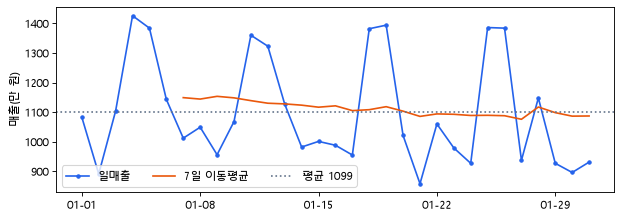

In [18]:
# 카페 1월 일매출(만 원): 평일 ~1000 · 주말 ~1350 (강의 100 · 107쪽)
# 왜 · 시간에 따른 변화와 요일 패턴을 꺾은선 · 이동 평균으로 보기 위해
day = pd.date_range("2025-01-01", periods=31, freq="D")  # 날짜 31개 · 간격 1일
weekend = day.dayofweek >= 5                             # 토(5) · 일(6)
cafe = pd.Series(np.where(weekend, 1350, 1000) + rng.normal(0, 60, 31), index=day).round()  # 일매출
# 차이
print("평일 평균:", cafe[~weekend].mean().round(1), "| 주말 평균:", cafe[weekend].mean().round(1))
# 간격 확인
print("빠진 날짜:", len(pd.date_range(day.min(), day.max()).difference(cafe.index)), "개")


fig, ax = plt.subplots(figsize=(9, 3))                                  # 가로로 긴 칸 (시간 축)
ax.plot(cafe.index, cafe.values, color="#2563eb", marker="o", ms=3, label="일매출")  # 원래 값
ax.plot(cafe.rolling(7).mean(), color="#ea580c", label="7일 이동평균")  # 요일 효과를 지운 추세
ax.axhline(cafe.mean(), color="#64748b", ls=":", label=f"평균 {cafe.mean():.0f}")  # 전체 평균선
ax.set_ylabel("매출(만 원)")                                            # 세로 = 값
ax.set_xticks(day[::7], day[::7].strftime("%m-%d"))                     # 7일 간격 눈금 (겹침 방지)
ax.legend(ncol=3)                                                       # 선 이름 한 줄
plt.show()                                                              # 그림 출력

**결과** · 예측 정답은 약 378만 원 높음 (1001.9 → 1379.9)

- `평일 평균: 1001.9 | 주말 평균: 1379.9` — 주말 봉우리 반복 = 주기적 패턴
- `빠진 날짜: 0 개` — 시간 간격이 일정 (누락 · 중복 없음)
- 그림 · 파란 선이 주말마다 솟고, 주황 7일 이동평균은 거의 평평, 회색 점선이 전체 평균

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>원래 값 선</td><td>일별 오르내림 · 이상일</td><td>주기 · 급등락 찾기</td></tr>
<tr><td>이동평균 선</td><td>주기를 지운 추세</td><td>증가 · 감소 판단</td></tr>
<tr><td>평균선</td><td>전체 수준 기준</td><td>위 · 아래 구간 비교</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 날짜가 빠지거나 중복되면 선이 왜곡 → 간격부터 확인
> - 하루 이틀 변동에 과하게 반응하지 않기 (잡음 vs 신호)

> ✅ **한 줄 정리** · 선그래프는 시간에 따른 추세 · 주기 · 이상일을 보여 주며, 평균선과 이동평균을 더하면 주기와 추세를 나눠 볼 수 있다.

**딥러닝 코드에서는**

- 학습 곡선 (epoch별 train · val loss)이 선그래프 · 들쭉날쭉하면 이동평균
- 시계열 예측의 입력 창(window)과 이동평균은 같은 생각 (RNN 정리본)

### 8-3. `A` 히트맵 · 지역 × 월 매출 · `ax.imshow` · `idxmax(axis=1)` · `colorbar` <sub>PDF 111 ~ 124쪽</sub>

> 🎯 **숫자 36개짜리 표에서 지역별 성수기를 한눈에 찾으려면?**

💡 **쉽게 말하면**

- 표의 칸마다 **값 크기를 색으로** 칠함.
- 빨간 칸만 찾으면 지역마다 언제 많이 팔렸는지 보임.

**실행 흐름**

1. 강의 112쪽 표 그대로 입력
2. 행마다 최댓값 달
3. 색 칸 + 숫자 + 색 막대(범례)

**먼저 예측** · 대구는 몇 월이 가장 높을까? — 답은 코드 실행 결과 아래에

지역별 최고 달: {'서울': '12월', '부산': '8월', '대구': '4월'}


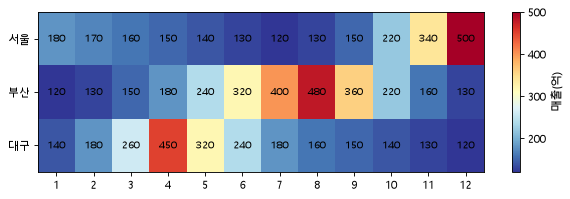

In [19]:
# 지역 x 월 매출(억) — 강의 112쪽 표 그대로
# 왜 · 행 · 열 두 범주의 값 크기를 색으로 한눈에 비교하기 위해
seoul = [180, 170, 160, 150, 140, 130, 120, 130, 150, 220, 340, 500]        # 1 ~ 12월
busan = [120, 130, 150, 180, 240, 320, 400, 480, 360, 220, 160, 130]        # 1 ~ 12월
daegu = [140, 180, 260, 450, 320, 240, 180, 160, 150, 140, 130, 120]        # 1 ~ 12월
sale = pd.DataFrame([seoul, busan, daegu], index=["서울", "부산", "대구"],  # 행 = 지역
                    columns=range(1, 13))                                   # 열 = 월
# 행마다 최댓값 위치
print("지역별 최고 달:", {k: f"{v}월" for k, v in sale.idxmax(axis=1).items()})


fig, ax = plt.subplots(figsize=(9, 2.6))                                     # 가로로 긴 칸
im = ax.imshow(sale, cmap="RdYlBu_r", aspect="auto")                         # 값 → 색 (빨강 = 큼)
for r in range(3):                                                           # 칸마다 숫자
    for c in range(12):                                                      # 12개월
        ax.text(c, r, sale.iat[r, c], ha="center", va="center", fontsize=9)  # 칸 가운데 값
ax.set_xticks(range(12), sale.columns)                                       # 가로 = 월
ax.set_yticks(range(3), sale.index)                                          # 세로 = 지역
fig.colorbar(im, ax=ax, label="매출(억)")                                    # 범례 = 색 ↔ 값
plt.show()                                                                   # 그림 출력

**결과** · 예측 정답은 4월 (450억) — 봄철 특화

- `지역별 최고 달: {'서울': '12월', '부산': '8월', '대구': '4월'}` — 서울 겨울 · 부산 여름 · 대구 봄
- 그림 · 서울은 오른쪽 끝, 부산은 가운데, 대구는 왼쪽에 빨간 칸

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>표</td><td>정확한 숫자</td><td>값 하나를 찾을 때</td></tr>
<tr><td>히트맵</td><td>색으로 패턴 · 집중 구간</td><td>행 × 열 조합 비교</td></tr>
<tr><td>상관계수 히트맵</td><td>변수 쌍마다 상관을 색으로</td><td>특성끼리 관계 훑기</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 색은 반드시 범례(색 막대)와 함께 읽기
> - 색 범위(vmin · vmax) 설정에 따라 같은 숫자도 다르게 보임

> ✅ **한 줄 정리** · 히트맵은 행 × 열 표의 값을 색으로 칠해 패턴 · 집중 구간 · 이상 신호를 한눈에 보여 주며, 색은 범례와 함께 읽는다.

**딥러닝 코드에서는**

- 혼동 행렬 · 어텐션 가중치 · 특성 상관 행렬을 히트맵으로
- `sns.heatmap(annot=True)`는 통계 파일별 2 문제 34에서

---
## 9. 종합 실습 · 카페 결제 데이터 한 장 요약

> **이 장의 흐름**
>
> - 1 ~ 8장을 결제 300건에 순서대로 적용
> - 숫자 요약에서 본 것을 그래프 4개로 확인

<img src="images/st1_practice.png" alt="유형 확인 → 대표값 · 퍼짐 → 도수분포표 → 그래프 4개" width="793">

**파이프라인 위치** · ① 데이터 이해 → ② 요약 → ③ 해석 → ④ 전달

> 🎯 **결제금액의 평균과 중앙값 중 무엇이 '보통 손님'을 더 잘 나타내는가?**

💡 **쉽게 말하면**

- **유형 → 대표값 · 퍼짐 → 표 → 그래프** 순서.
- 질문마다 변수 개수 · 유형을 보고 그래프를 고름.

**실행 흐름**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">단계</th><th style="text-align: left;">하는 일</th><th style="text-align: left;">쓰는 문법</th></tr>
</thead>
<tbody>
<tr><td>1</td><td>열마다 유형 확인</td><td>1-1</td></tr>
<tr><td>2</td><td>평균 · 중앙값 · 표준편차 · IQR · 이상점 후보</td><td>4장</td></tr>
<tr><td>3</td><td>5,000원 구간 도수분포표 · 최빈 구간</td><td>2장</td></tr>
<tr><td>4</td><td>범주 1개 → 막대 · 수치 1개 → 히스토그램</td><td>5 · 6 · 3장</td></tr>
<tr><td>5</td><td>범주 + 수치 → 박스플롯 · 순서 + 수치 → 선</td><td>7 · 8장</td></tr>
</tbody></table>

**먼저 예측** · 평균과 중앙값 중 어느 쪽이 클까? — 답은 코드 실행 결과 아래에

In [20]:
# 카페 결제 300건: 결제수단(범주) · 요일(범주, 순서) · 결제금액(연속)
# 왜 · 앞에서 배운 요약 · 그래프를 한 데이터에 모두 적용하기 위해
n = 300                                                                        # 결제 건수
method = rng.choice(["카드", "현금", "간편결제"], n, p=[0.6, 0.15, 0.25])      # 범주
weekday = rng.choice(list("월화수목금토일"), n)                                # 순서 있는 범주
big = [52000, 61000, 48000, 75000, 58000, 66000]                               # 단체 주문 6건
price = np.r_[rng.lognormal(np.log(9000), 0.4, n - 6), big].round(-2)          # 대부분 1만 원 안팎
shop = pd.DataFrame({"결제수단": method, "요일": weekday, "결제금액": price})  # 열 3개
print(shop.dtypes.astype(str).to_dict())                                       # 1단계: 유형 확인


# 2단계: 대표값과 퍼짐
# 왜 · 그래프를 그리기 전에 숫자로 먼저 분포를 파악하기 위해
m = shop["결제금액"]                                                              # 연속형 열
print(f"평균 {m.mean():.0f} | 중앙값 {m.median():.0f} | 표준편차 {m.std():.0f}")  # 평균 > 중앙값?
q1, q3 = m.quantile([0.25, 0.75])                                                 # 사분위수
print(f"IQR {q3 - q1:.0f} | 이상점 후보 {(m > q3 + 1.5 * (q3 - q1)).sum()}건")    # 큰 결제


# 3단계: 도수분포표 (5,000원 구간)
# 왜 · 금액 분포를 구간별 개수로 정리하기 위해
# 구간별 개수
table = pd.cut(m, bins=range(0, 80001, 5000), right=False).value_counts().sort_index()
top3 = round(table.nlargest(3).sum() / n, 3)                     # 개수가 많은 세 구간의 비율 합
print("최빈 구간:", table.idxmax(), "| 상위 3구간 비율:", top3)  # 가장 흔한 금액대

{'결제수단': 'str', '요일': 'str', '결제금액': 'float64'}
평균 11064 | 중앙값 9500 | 표준편차 8205
IQR 5400 | 이상점 후보 11건
최빈 구간: [5000, 10000) | 상위 3구간 비율: 0.89


**실행 흐름**

1. 요일 순서 정하기
2. 질문 4개에 맞는 그래프를 한 판(2 × 2)에 그리기
3. 그림 출력

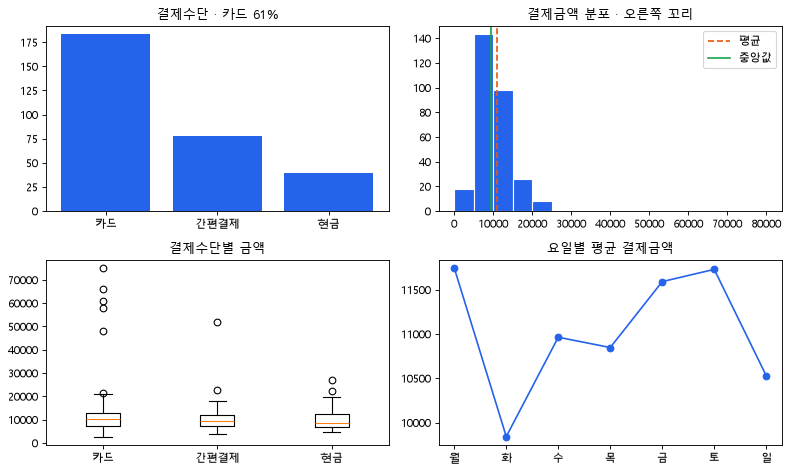

요일별 평균 최고: 월 | 최저: 화


In [21]:
# 4단계: 질문마다 맞는 그래프 4개를 한 판에
# 왜 · 질문마다 다른 변수 유형에 맞는 그래프를 고르기 위해
order = list("월화수목금토일")                                           # 요일 순서
fig, axes = plt.subplots(2, 2, figsize=(10, 6))                          # 2행 2열
cnt = shop["결제수단"].value_counts()                                    # 범주 1개 → 막대
axes[0, 0].bar(cnt.index, cnt.values, color="#2563eb")                   # 왼쪽 위 · 개수
axes[0, 0].set_title(f"결제수단 · {cnt.idxmax()} {cnt.max() / n:.0%}")   # 발견한 사실
axes[0, 1].hist(m, bins=range(0, 80001, 5000), color="#2563eb", edgecolor="white")  # 수치 1개
axes[0, 1].axvline(m.mean(), color="#ea580c", ls="--", label="평균")     # 꼬리에 끌린 평균
axes[0, 1].axvline(m.median(), color="#16a34a", label="중앙값")          # 보통 손님
axes[0, 1].legend()                                                      # 선 이름
axes[0, 1].set_title("결제금액 분포 · 오른쪽 꼬리")                      # 오른쪽 위
groups = [m[shop["결제수단"] == k] for k in cnt.index]                   # 범주 + 수치 → 박스플롯
axes[1, 0].boxplot(groups, tick_labels=cnt.index)                        # 결제수단마다 상자 1개
axes[1, 0].set_title("결제수단별 금액")                                  # 왼쪽 아래
by_day = shop.groupby("요일")["결제금액"].mean().reindex(order)          # 순서 + 수치 → 선
axes[1, 1].plot(order, by_day.values, marker="o", color="#2563eb")       # 월 ~ 일 순서
axes[1, 1].set_title("요일별 평균 결제금액")                             # 오른쪽 아래
plt.tight_layout()                                                       # 칸 간격 정리
plt.show()                                                               # 그림 출력
print("요일별 평균 최고:", by_day.idxmax(), "| 최저:", by_day.idxmin())  # 선그래프에서 읽은 값

**결과** · 예측 정답은 평균(11064) > 중앙값(9500) — 큰 결제 6건이 평균을 끌어올림

- `{'결제수단': 'str', '요일': 'str', '결제금액': 'float64'}` — 범주 2개 · 연속형 1개
- `평균 11064 | 중앙값 9500 | 표준편차 8205` — 평균 > 중앙값 → 오른쪽 꼬리
- `IQR 5400 | 이상점 후보 11건` — 큰 결제 6건 + 꼬리 쪽 일반 결제
- `최빈 구간: [5000, 10000) | 상위 3구간 비율: 0.89` — 결제 대부분이 5천 ~ 2만 원
- `요일별 평균 최고: 월 | 최저: 화` — 무작위 데이터라 요일 차이는 작음 · 선 높낮이를 과장해 읽지 않기

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>평균</td><td>큰 결제에 끌려감</td><td>총매출 = 평균 × 건수 계산</td></tr>
<tr><td>중앙값</td><td>보통 손님 한 명</td><td>'일반 고객'을 설명할 때</td></tr>
<tr><td>박스플롯 점</td><td>이상점 후보</td><td>단체 주문 · 입력 오류 확인</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 선그래프 세로축이 1만 ~ 1.2만이라 차이가 커 보임 · 실제 차이는 2천 원 안팎
> - 이상점 후보 11건은 지우기 전에 원인 확인

> ✅ **한 줄 정리** · 새 데이터는 유형 → 대표값 · 퍼짐 → 도수분포표 → 질문별 그래프 순서로 요약하고, 꼬리가 길면 중앙값으로 보통 값을 말한다.

**딥러닝 코드에서는**

- 모델 학습 전 EDA 체크리스트가 이 순서
- `df.describe()` + 히스토그램 + 박스플롯을 먼저 보고 정규화 · 이상치 처리를 정함

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">학습 목표</th><th style="text-align: left;">할 수 있게 된 것</th><th style="text-align: left;">확인 위치</th></tr>
</thead>
<tbody>
<tr><td>1. 유형 → 그래프</td><td>혈압 = 연속 · 걸음 수 = 이산 · 결제수단 코드 = 범주, 범주는 막대 · 연속은 히스토그램</td><td>1장 · 5장</td></tr>
<tr><td>2. 도수분포표</td><td>키 200명 → 160~165 구간 84명 · 170 미만 96.5%</td><td>2장</td></tr>
<tr><td>3. 대표값 · 퍼짐 계산</td><td>대표 연봉 한 명에 평균 3340 → 11116.7 · 중앙값은 3450, 분산 10.4 · 13.0</td><td>4장</td></tr>
<tr><td>4. 분포 읽기</td><td>평균 57만 vs 중앙값 25만 · bins 3 · 6 · 40 · 박스 IQR 3.7 vs 21.1</td><td>3장 · 7장</td></tr>
<tr><td>5. 그래프 5종</td><td>막대 · 원(3개만) · 산점도(상관 0.988 → 0.847) · 선(주말 효과) · 히트맵(지역별 성수기)</td><td>6 · 8장</td></tr>
</tbody></table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td><code>A</code></td><td>데이터 유형</td><td>범주 · 이산 · 연속 · 숫자 코드는 범주</td><td>라벨 <code>y</code> · one-hot</td></tr>
<tr><td><code>A</code></td><td>도수분포표</td><td>구간 · 도수 · 상대 · 누적</td><td><code>np.histogram</code> · binning</td></tr>
<tr><td><code>A</code></td><td>평균 vs 중앙값</td><td>극단값에 약함 vs 강함</td><td>MSE vs MAE</td></tr>
<tr><td><code>A</code></td><td>분산 · 표준편차</td><td>편차² 평균 · 제곱근 · ddof</td><td>정규화 · BatchNorm</td></tr>
<tr><td><code>A</code></td><td>IQR · fence</td><td>Q3 - Q1 · 1.5배 밖 = 후보</td><td>RobustScaler</td></tr>
<tr><td><code>A</code></td><td>차트 고르기</td><td>변수 개수 + 유형</td><td>학습 곡선 · 혼동 행렬</td></tr>
<tr><td><code>B</code></td><td>원그래프</td><td>4 ~ 5개 이하만</td><td>구성비 발표</td></tr>
</tbody></table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

*섹션 → 🎯 질문*

- **1-1** · 결제수단 코드 1 · 2 · 3의 평균은 왜 뜻이 없는가?
- **1-2** · 결제금액을 손님마다 막대로 그리면?
- **2-1** · 도수분포표 6단계는?
- **2-2** · 중앙값 구간은 어떻게 찾는가?
- **2-3** · 도수분포표와 히스토그램의 관계는?
- **3-1** · 꼬리가 긴 분포에서 평균과 중앙값은?
- **3-2** · bins가 너무 많으면?
- **4-1** · 극단값에 강한 대표값은?
- **4-2** · np.var와 pandas var가 다른 이유는?
- **4-3** · IQR과 fence는?
- **5-1** · 광고비 vs 매출은 어떤 그래프인가?
- **6-1** · 막대그래프에서 꼭 지킬 것은?
- **6-2** · 원그래프는 언제 쓰는가?
- **7-1** · 박스플롯 상자 길이가 뜻하는 것은?
- **7-2** · 극단값이 양쪽에 하나씩 들어오면?
- **8-1** · 상관과 인과의 차이는?
- **8-2** · 7일 이동평균을 그리는 이유는?
- **8-3** · 히트맵 색을 읽을 때 꼭 볼 것은?

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**7-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**7-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**8-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**8-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**8-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. `x = pd.Series([2, 4, 4, 5, 7, 9, 30])`의 평균 · 중앙값 · 최빈값 출력
2. Q1 · Q3 · 위쪽 fence(Q3 + 1.5×IQR)를 출력하고 fence 위의 값을 리스트로 출력

In [22]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 2-1의 키 데이터를 10cm 구간(`[140, 150, 160, 170, 180]`)으로 다시 나누면 최빈 구간과 그 도수는?
2. 4-1의 직원 연봉에 3,300만 원인 직원을 한 명 더 넣으면(대표 포함 7명) 중앙값은?
3. 8-3 히트맵에서 '1년 합계가 가장 큰 지역'을 코드 한 줄로 찾기

In [23]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

*섹션 → 답*

- **1-1** · 코드는 이름표(범주)라 개수 · 비율로 요약
- **1-2** · 막대가 90개 넘게 생겨 패턴이 안 보임 → 히스토그램
- **2-1** · 범위 → 구간 → 계급값 → 도수 → 상대도수 → 누적
- **2-2** · 누적상대도수가 처음 0.5 이상인 구간
- **2-3** · 표의 한 행 = 막대 1개 · 같은 정보
- **3-1** · 평균이 꼬리 쪽으로 끌려 중앙값보다 큼
- **3-2** · 잡음 · 빈 구간이 생겨 모양이 들쭉날쭉
- **4-1** · 중앙값
- **4-2** · ddof 기본값 0(÷n) vs 1(÷(n-1))
- **4-3** · Q3 - Q1 · Q1 - 1.5×IQR ~ Q3 + 1.5×IQR 밖이 이상점 후보
- **5-1** · 수치 + 수치 → 산점도
- **6-1** · 막대 사이 간격 · 세로축 0부터
- **6-2** · 항목 4 ~ 5개 이하의 구성비
- **7-1** · IQR (가운데 50%의 폭)
- **7-2** · 평균은 그대로일 수 있지만 표준편차가 크게 커짐
- **8-1** · 같이 움직임 vs 원인 · 산점도는 상관만 보여 줌
- **8-2** · 요일 효과를 지우고 추세만 보려고
- **8-3** · 범례(색 막대)와 색 범위

#### 코드 문제 답

```python
x = pd.Series([2, 4, 4, 5, 7, 9, 30])
print(x.mean(), x.median(), x.mode().tolist())  # 8.714285714285714 5.0 [4]
q1, q3 = x.quantile([0.25, 0.75])
print(q1, q3, q3 + 1.5 * (q3 - q1))  # 4.0 8.0 14.0
print(x[x > q3 + 1.5 * (q3 - q1)].tolist())  # [30]
```

#### 변형 문제 답

*문제 → 답*

- **1** · `[160, 170)` 구간 · 84 + 39 = 123명
- **2** · 3400 — 정렬하면 3000 · 3200 · 3300 · **3400** · 3500 · 3600 · 50000의 가운데(4번째)
- **3** · `sale.sum(axis=1).idxmax()` → 부산 (2890억) · 서울 2390억 · 대구 2470억

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">틀린 내용</th><th style="text-align: left;">틀린 이유</th><th style="text-align: left;">올바른 원칙</th><th style="text-align: left;">재발 방지 질문</th></tr>
</thead>
<tbody>
<tr><td>(예) 결제금액 '평균 고객'이 평균 금액을 쓴다고 답함</td><td>평균 = 보통 사람이라고 착각</td><td>꼬리가 길면 평균은 꼬리 쪽 · 보통은 중앙값</td><td>히스토그램을 먼저 그렸나?</td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
</tbody></table>

---
## 면접 30초 답변

**Q1. 평균과 중앙값은 언제 각각 쓰나요?**
> - 평균은 모든 값을 반영해 대칭 분포나 합계 계산에 적합하지만 극단값에 끌려갑니다.
> - 소득이나 결제액처럼 오른쪽 꼬리가 긴 분포에서는 중앙값이 보통 값을 더 잘 나타냅니다.

**Q2. 분산과 표준편차의 차이, 그리고 ddof는 무엇인가요?**
> - 분산은 편차 제곱의 평균이라 단위가 제곱이고, 표준편차는 그 제곱근이라 원래 단위입니다.
> - ddof는 나누는 수를 n에서 뺄 값으로, NumPy는 0, pandas는 1이 기본이라 값이 조금 다릅니다.

**Q3. 이상치를 어떻게 찾고 처리하나요?**
> - 박스플롯이나 IQR 기준(Q1 - 1.5×IQR, Q3 + 1.5×IQR) 밖의 값을 이상점 후보로 표시합니다.
> - 바로 지우지 않고 입력 오류인지 실제 극단값인지 확인한 뒤, 필요하면 중앙값 · IQR 기반 방법을 씁니다.

**Q4. 그래프는 어떤 기준으로 고르나요?**
> - 변수 개수와 유형으로 고릅니다.
> - 범주 하나는 막대, 수치 하나는 히스토그램이나 박스플롯, 수치 둘은 산점도, 시간에 따른 수치는 선그래프, 두 범주 조합의 값은 히트맵을 씁니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>pd.api.types.is_numeric_dtype()</code></td><td>pandas</td><td>숫자 열인지</td><td>1-1 <code>is_numeric_dtype(quiz[col])</code></td></tr>
<tr><td><code>value_counts()</code></td><td>pandas Series</td><td>범주별 개수</td><td>1-2 <code>pay["결제수단"].value_counts()</code></td></tr>
<tr><td><code>pd.cut(right=False)</code></td><td>pandas</td><td>구간 나누기</td><td>2-1 <code>pd.cut(height, bins=bins, right=False)</code></td></tr>
<tr><td><code>cumsum()</code></td><td>pandas Series</td><td>누적</td><td>2-1 <code>freq["도수"].cumsum()</code></td></tr>
<tr><td><code>np.histogram()</code></td><td>numpy</td><td>구간별 개수</td><td>2-3 <code>np.histogram(height, bins=bins)</code></td></tr>
<tr><td><code>mean() · median() · mode()</code></td><td>pandas Series</td><td>대표값 3가지</td><td>4-1 <code>score.mean()</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>np.var() · np.std() · ddof</code></td><td>numpy</td><td>분산 · 표준편차</td><td>4-2 <code>np.var(x)</code> · <code>s.std(ddof=1)</code></td></tr>
<tr><td><code>quantile() · describe()</code></td><td>pandas Series</td><td>사분위수 · 요약</td><td>4-3 <code>s.quantile([0.25, 0.5, 0.75])</code></td></tr>
<tr><td><code>ax.bar · ax.barh · ax.pie</code></td><td>matplotlib</td><td>막대 · 원</td><td>6-1 · 6-2</td></tr>
<tr><td><code>ax.hist(bins=)</code></td><td>matplotlib</td><td>히스토그램</td><td>3-2 <code>ax.hist(height, bins=b)</code></td></tr>
<tr><td><code>ax.boxplot(tick_labels=)</code></td><td>matplotlib</td><td>박스플롯</td><td>7-1 <code>ax.boxplot([class_a, class_b], ...)</code></td></tr>
<tr><td><code>ax.scatter · np.corrcoef()</code></td><td>matplotlib · numpy</td><td>산점도 · 상관계수</td><td>8-1</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>ax.plot · rolling().mean()</code></td><td>matplotlib · pandas</td><td>선그래프 · 이동평균</td><td>8-2 <code>cafe.rolling(7).mean()</code></td></tr>
<tr><td><code>ax.imshow · fig.colorbar</code></td><td>matplotlib</td><td>히트맵 · 범례</td><td>8-3</td></tr>
</tbody></table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">✅ 할 것</th><th style="text-align: left;">⚠️ 하지 말 것</th></tr>
</thead>
<tbody>
<tr><td>그래프 전에 열마다 유형 확인</td><td>숫자 dtype이면 무조건 평균</td></tr>
<tr><td>평균과 중앙값을 함께 보고하기</td><td>평균 하나로 '보통 고객' 설명</td></tr>
<tr><td>fence 밖 값은 원인 확인 후 처리</td><td>이상점 후보를 바로 삭제</td></tr>
<tr><td>원그래프는 항목 4 ~ 5개 이하</td><td>비슷한 값 8개를 원그래프로</td></tr>
<tr><td>산점도의 관계는 '상관'으로 말하기</td><td>상관을 인과로 단정</td></tr>
</tbody></table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">짝</th><th style="text-align: left;">차이</th><th style="text-align: left;">결론</th></tr>
</thead>
<tbody>
<tr><td>막대 vs 히스토그램</td><td>범주별 vs 구간별 · 간격 vs 붙음</td><td>유형으로 고름</td></tr>
<tr><td>평균 vs 중앙값</td><td>극단값에 약함 vs 강함</td><td>꼬리가 길면 중앙값</td></tr>
<tr><td>분산 vs 표준편차</td><td>단위² vs 원래 단위</td><td>보고는 표준편차</td></tr>
<tr><td><code>np.std</code> vs <code>Series.std</code></td><td>ddof 0 vs 1</td><td>비교할 땐 ddof 맞추기</td></tr>
<tr><td>표준편차 vs IQR</td><td>평균 기준 vs 가운데 50%</td><td>치우치면 IQR</td></tr>
<tr><td>상관 vs 인과</td><td>같이 움직임 vs 원인</td><td>산점도는 상관만</td></tr>
</tbody></table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">언제</th><th style="text-align: left;">할 일</th><th style="text-align: left;">걸리는 시간</th></tr>
</thead>
<tbody>
<tr><td>내일</td><td>기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td><td>15분</td></tr>
<tr><td>3일 뒤</td><td>변형 문제 3개 · 4-2 분산을 손으로 다시 계산</td><td>20분</td></tr>
<tr><td>7일 뒤</td><td>9장 종합 실습을 다른 seed로 다시 짜고 그래프 4개 해석</td><td>30분</td></tr>
<tr><td>14일 뒤</td><td>통계 파일별 2(그래프 문법) 1 · 2장과 함께 ✅ 줄만 읽기</td><td>15분</td></tr>
</tbody></table>

---
## 부록

### 이 노트북을 만든 방법

- 원본 · `02_데이터 요약과 시각화.pdf` 131쪽 (코드 없음 · 슬라이드 표 · 그래프)
- 슬라이드의 표 · 그래프 숫자(키 도수 1 · 15 · 54 · 84 · 39 · 7, 지역별 매출 표 등)를 코드로 같은 값으로 만들어 실행
- 강의가 '진행 예정'으로 남긴 평균 · 중앙값 · 분산 · 표준편차는 4장에서 보강 (사용자 요청: 대표값 · 그래프 해석 우선)
- 모든 코드는 실행한 출력과 함께 저장 · 형식 v2.1 (FORMAT_V2.md 1 ~ 7절)

### 읽는 법

*표시 → 의미*

- **`A` · `B`** · **A** 딥러닝 코드에 바로 나오는 필수 · **B** 알아두면 되는 것
- **🎯** · 이번 섹션에서 답해야 할 질문
- **💡** · 쉬운 설명 · 비유
- **⚠️** · 자주 하는 실수
- **✅** · 기억할 결론 = 🎯 질문의 답

- **섹션 앞부분** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드
- **섹션 뒷부분** · 결과(예측 정답 · 출력 줄) → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리
- **코드 주석** · 코드 위는 이 단계에서 하는 일, 코드 옆은 그 줄이 필요한 이유 (줄마다 · 열 맞춤)

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">원본</th><th style="text-align: left;">내용</th><th style="text-align: left;">이 노트북</th></tr>
</thead>
<tbody>
<tr><td>1 ~ 5쪽</td><td>분석가의 업무 · 숫자 더미 → 요약 도구</td><td>0 원본 흐름 · 3-1 · 4-1</td></tr>
<tr><td>6 ~ 13 · 37 ~ 43쪽</td><td>데이터 유형 · 미니퀴즈</td><td>1-1</td></tr>
<tr><td>9 ~ 11쪽</td><td>유형별 그래프 · 실무 예시</td><td>1-2</td></tr>
<tr><td>14 ~ 22쪽</td><td>도수분포표 6단계 · 인사이트 · 히스토그램 변환</td><td>2-1 · 2-2 · 2-3</td></tr>
<tr><td>23 ~ 34쪽</td><td>히스토그램 정의 · 필요성 · 읽을 것 · bin</td><td>3-1 · 3-2</td></tr>
<tr><td>(보강)</td><td>평균 · 중앙값 · 최빈값 · 분산 · 표준편차</td><td>4-1 · 4-2</td></tr>
<tr><td>44 ~ 51 · 125 ~ 131쪽</td><td>차트 치트 1 · 2 · 결론</td><td>5-1</td></tr>
<tr><td>52 ~ 66쪽</td><td>막대그래프 · 원그래프</td><td>6-1 · 6-2</td></tr>
<tr><td>67 ~ 84쪽</td><td>박스플롯 · 다섯 숫자 · IQR · fence · 이상치 포함 vs 제외</td><td>4-3 · 7-1 · 7-2</td></tr>
<tr><td>85 ~ 98쪽</td><td>산점도 · 상관 ≠ 인과 · 예외점</td><td>8-1</td></tr>
<tr><td>99 ~ 110쪽</td><td>선그래프 · 평일 vs 주말 · 실습 가이드</td><td>8-2</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">원본</th><th style="text-align: left;">내용</th><th style="text-align: left;">이 노트북</th></tr>
</thead>
<tbody>
<tr><td>111 ~ 124쪽</td><td>히트맵 · 지역별 월 매출</td><td>8-3</td></tr>
<tr><td>(종합)</td><td>새 데이터에 1 ~ 8장 적용</td><td>9 종합 실습</td></tr>
</tbody></table>

### 전체 코드

1 ~ 9장 코드를 장별 셀로 모음. **위에서부터 이 셀들만 실행해도 전체가 동작**하며, 각 블록 머리 주석의 번호가 섹션.

**실행 흐름**

1. 1-1 변수 유형 나누기
2. 1-2 유형에 맞는 그래프 · 틀린 그래프 비교

혈압 | 양적(수치) · 연속형
혈액형 | 질적(범주) · 명목형
걸음수 | 양적(수치) · 이산형
브랜드 | 질적(범주) · 명목형
코드 평균: 1.57 ← 뜻 없는 숫자
코드별 개수: {1: 4, 2: 2, 3: 1}
결제수단 개수: {'카드': 70, '현금': 30}
결제금액 서로 다른 값: 94 개


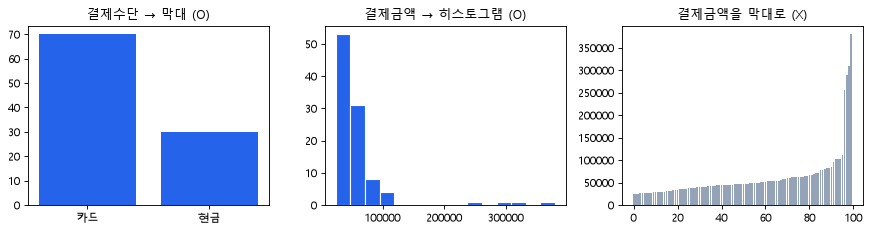

In [24]:
# ---------- 1-1 ----------
# 강의 12쪽 미니퀴즈: 변수 4개를 양적(수치) · 질적(범주)으로 나누기
# 왜 · 변수 유형을 먼저 정해야 맞는 요약 · 그래프를 고를 수 있기 때문에
quiz = pd.DataFrame({                                  # 열 = 변수 · 행 = 사람 3명
    "혈압": [118.5, 125.0, 132.4],                     # mmHg · 소수 가능
    "혈액형": ["A", "O", "AB"],                        # 종류만 있음
    "걸음수": [10000, 8421, 12030],                    # 하루 걸음 · 셀 수 있음
    "브랜드": ["삼성", "애플", "삼성"],                # 종류만 있음
})
# 강의 7 · 8 · 42쪽 기준
detail = {"혈압": "연속형", "혈액형": "명목형", "걸음수": "이산형", "브랜드": "명목형"}
for col in quiz.columns:                               # 열마다
    is_num = pd.api.types.is_numeric_dtype(quiz[col])  # 숫자 열인가
    kind = "양적(수치)" if is_num else "질적(범주)"    # 큰 분류
    print(f"{col} | {kind} · {detail[col]}")           # 큰 분류 · 세부 유형


# 숫자로 적혀 있어도 범주인 경우: 결제수단 코드 1 = 카드 · 2 = 현금 · 3 = 간편결제
# 왜 · 숫자 모양만 보고 평균을 내는 실수를 막기 위해
pay_code = pd.Series([1, 2, 1, 1, 3, 1, 2])                            # 숫자지만 '종류'
print("코드 평균:", round(pay_code.mean(), 2), "← 뜻 없는 숫자")       # 1.57 = ?
print("코드별 개수:", pay_code.value_counts().sort_index().to_dict())  # 범주는 개수로 요약


# ---------- 1-2 ----------
# 결제 100건: 결제수단(범주) · 결제금액(연속) — 강의 9 ~ 11쪽 예
# 왜 · 범주 · 연속 변수가 함께 있는 실제 데이터 모양을 만들기 위해
# 대부분 5만 원 근처 · 큰 결제 4건
amount = np.r_[rng.lognormal(10.7, 0.35, 96), [255000, 290000, 310000, 380000]]
pay = pd.DataFrame({"결제수단": ["카드"] * 70 + ["현금"] * 30,    # 범주형
                    "결제금액": amount.round(-2)})                # 연속형 · 100원 단위
counts = pay["결제수단"].value_counts()                           # 범주 → 개수
print("결제수단 개수:", counts.to_dict())                         # 막대 2개면 충분
print("결제금액 서로 다른 값:", pay["결제금액"].nunique(), "개")  # 막대로 그리면 이만큼 막대


# 맞는 그래프 (막대 · 히스토그램) vs 틀린 그래프 (금액마다 막대)
# 왜 · 변수 유형에 맞지 않는 그래프가 왜 읽기 어려운지 나란히 보기 위해
fig, axes = plt.subplots(1, 3, figsize=(11, 3))                               # 가로 3칸
axes[0].bar(counts.index, counts.values, color="#2563eb")                     # 범주 → 막대
axes[0].set_title("결제수단 → 막대 (O)")                                      # 맞는 짝
axes[1].hist(pay["결제금액"], bins=15, color="#2563eb", edgecolor="white")    # 연속 → 구간별 개수
axes[1].set_title("결제금액 → 히스토그램 (O)")                                # 맞는 짝
axes[2].bar(range(len(pay)), pay["결제금액"].sort_values(), color="#94a3b8")  # 손님 1명씩 막대
axes[2].set_title("결제금액을 막대로 (X)")                                    # 패턴이 안 보임
plt.tight_layout()                                                            # 칸 간격 정리
plt.show()                                                                    # 그림 출력

**실행 흐름**

1. 2-1 도수분포표 만들기
2. 2-2 표에서 읽을 것
3. 2-3 히스토그램

1단계 범위: 146.11 ~ 172.74 | 학생 수: 200
           계급값  도수   상대도수  누적도수  누적상대도수
145~150  147.5   1  0.005     1   0.005
150~155  152.5  15  0.075    16   0.080
155~160  157.5  54  0.270    70   0.350
160~165  162.5  84  0.420   154   0.770
165~170  167.5  39  0.195   193   0.965
170~175  172.5   7  0.035   200   1.000
최빈 구간: 160~165 (42.0%)
중앙값 구간: 160~165
170cm 미만: 96.5%
실제 중앙값: 161.685 | 170 미만 실제 비율: 0.965
np.histogram 도수: [1, 15, 54, 84, 39, 7]
도수분포표와 같은가: True


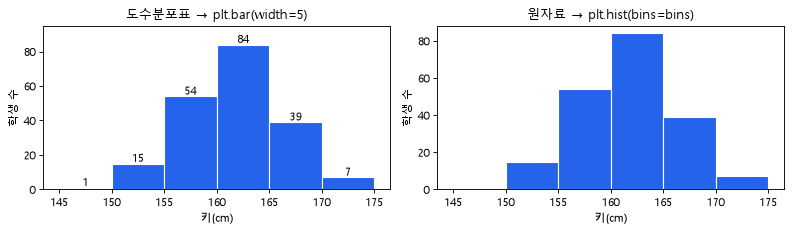

In [25]:
# ---------- 2-1 ----------
# 여중학생 200명의 키 (강의 15 · 17 · 18쪽: 145 ~ 173cm · 구간 5cm · 도수 1 · 15 · 54 · 84 · 39 · 7)
# 왜 · 강의 도수분포표와 같은 분포의 데이터를 만들어 숫자를 맞춰 보기 위해
lows, ns = [145, 150, 155, 160, 165, 170], [1, 15, 54, 84, 39, 7]  # 구간 시작 · 강의 표의 도수
height = np.concatenate([rng.uniform(lo, lo + (3 if lo == 170 else 5), n)  # 마지막 구간은 173cm까지
                         for lo, n in zip(lows, ns)]).round(2)     # 소수 둘째 자리
rng.shuffle(height)                                                # 순서 섞기 (실제 데이터처럼)
print("1단계 범위:", height.min(), "~", height.max(), "| 학생 수:", height.size)  # 최솟값 · 최댓값


# 2 ~ 6단계: 구간 나누기 → 계급값 → 도수 → 상대도수 → 누적
# 왜 · 도수분포표를 손계산 순서대로 만들어 각 열의 뜻을 이해하기 위해
bins = [145, 150, 155, 160, 165, 170, 175]               # 5cm 간격 경계
cut = pd.cut(height, bins=bins, right=False)             # [150, 155)처럼 왼쪽 포함 · 오른쪽 제외
freq = cut.value_counts().sort_index().to_frame("도수")  # 구간별 개수 (구간 순서대로)
freq.index = [f"{b}~{b + 5}" for b in bins[:-1]]         # 표에 보일 이름
freq.insert(0, "계급값", [b + 2.5 for b in bins[:-1]])   # 구간의 가운데
freq["상대도수"] = freq["도수"] / freq["도수"].sum()     # 도수 ÷ 전체
freq["누적도수"] = freq["도수"].cumsum()                 # 개수 누적
freq["누적상대도수"] = freq["상대도수"].cumsum()         # 비율 누적
print(freq.round(3))                                     # 도수분포표


# ---------- 2-2 ----------
# 도수분포표에서 읽을 것 3가지 (강의 19쪽)
# 왜 · 표에서 최빈 구간 · 중앙값 구간 · 누적 비율을 바로 읽어 내기 위해
mode_bin = freq["도수"].idxmax()                                 # 도수가 가장 큰 구간
median_bin = freq.index[(freq["누적상대도수"] >= 0.5).argmax()]  # 누적 비율이 처음 0.5 이상
below_170 = freq.loc["145~150":"165~170", "상대도수"].sum()      # 170cm 미만 구간 합
print(f"최빈 구간: {mode_bin} ({freq.loc[mode_bin, '상대도수']:.1%})")  # 가장 많이 모인 곳
print(f"중앙값 구간: {median_bin}")                              # 100번째 · 101번째 학생이 있는 곳
print(f"170cm 미만: {below_170:.1%}")                            # 누적상대도수 0.965


# 원자료로 확인: 표에서 읽은 값과 맞는가
# 왜 · 구간으로 요약한 값이 원자료와 얼마나 맞는지 검증하기 위해
# 표 ↔ 원자료
print("실제 중앙값:", np.median(height), "| 170 미만 실제 비율:", (height < 170).mean())


# ---------- 2-3 ----------
# 도수분포표 → 히스토그램: 표의 한 행 = 막대 1개 (강의 20 · 21쪽)
# 왜 · 히스토그램이 도수분포표를 그림으로 옮긴 것임을 확인하기 위해
counts, edges = np.histogram(height, bins=bins)  # 원자료에서 바로 구간별 개수
print("np.histogram 도수:", counts.tolist())     # 마지막 구간은 175 포함
print("도수분포표와 같은가:", (counts == freq["도수"].to_numpy()).all())  # 같은 표


fig, axes = plt.subplots(1, 2, figsize=(10, 3))     # 표로 그리기 vs 원자료로 그리기
# 막대 폭 = 구간 폭
axes[0].bar(freq["계급값"], freq["도수"], width=5, color="#2563eb", edgecolor="white")
for x, n in zip(freq["계급값"], freq["도수"]):      # 막대 위 숫자
    axes[0].text(x, n + 1, n, ha="center")          # 도수 표시
axes[0].set_title("도수분포표 → plt.bar(width=5)")  # 표에서 그림
axes[0].set_ylim(0, 95)                             # 막대 위 숫자 자리
axes[1].hist(height, bins=bins, color="#2563eb", edgecolor="white")  # 원자료에서 그림
axes[1].set_title("원자료 → plt.hist(bins=bins)")   # 같은 모양
for ax in axes:                                     # 두 칸 공통
    ax.set_xlabel("키(cm)")                         # 가로 = 구간
    ax.set_ylabel("학생 수")                        # 세로 = 도수
plt.tight_layout()                                  # 칸 간격 정리
plt.show()                                          # 그림 출력

**실행 흐름**

1. 3-1 꼬리가 긴 분포
2. 3-2 bins에 따른 모양 차이

평균 58.8만 원 | 중앙값 25.0만 원
평균보다 적게 쓴 고객: 91%


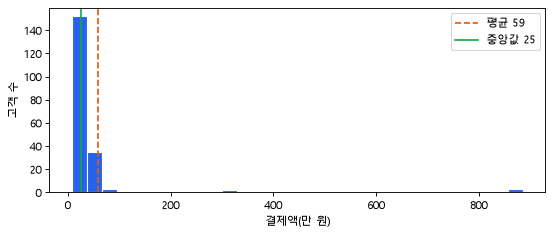

bins= 3 | 막대 3개 | 빈 구간 0개 | 가장 큰 막대 116명
bins= 6 | 막대 6개 | 빈 구간 0개 | 가장 큰 막대 71명


bins=40 | 막대 40개 | 빈 구간 6개 | 가장 큰 막대 17명


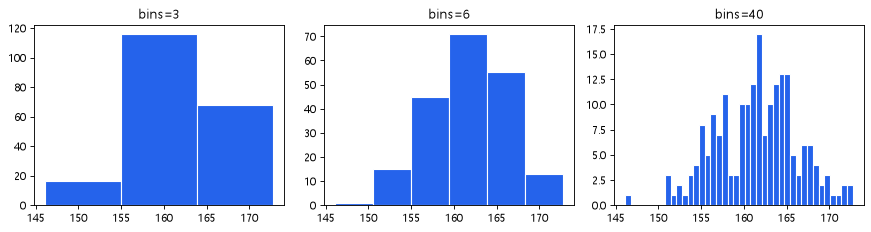

In [26]:
# ---------- 3-1 ----------
# 백화점 고객 200명 결제액 (강의 27 · 28쪽): 대부분 작고 일부만 매우 큼
# 왜 · 한쪽으로 꼬리가 긴 분포에서 평균이 끌려가는 상황을 재현하기 위해
spend = np.r_[rng.lognormal(np.log(25), 0.5, 190), rng.uniform(300, 900, 10)].round()  # 만 원
print(f"평균 {spend.mean():.1f}만 원 | 중앙값 {np.median(spend):.1f}만 원")  # 평균이 훨씬 큼
print(f"평균보다 적게 쓴 고객: {(spend < spend.mean()).mean():.0%}")         # '평균 고객'은 소수


fig, ax = plt.subplots(figsize=(8, 3))                       # 한 칸
ax.hist(spend, bins=30, color="#2563eb", edgecolor="white")  # 분포 모양
# 꼬리에 끌려감
ax.axvline(spend.mean(), color="#ea580c", ls="--", label=f"평균 {spend.mean():.0f}")
ax.axvline(np.median(spend), color="#16a34a", label=f"중앙값 {np.median(spend):.0f}")  # 가운데 고객
ax.set_xlabel("결제액(만 원)")                               # 가로 = 값 구간
ax.set_ylabel("고객 수")                                     # 세로 = 개수
ax.legend()                                                  # 선 이름
plt.show()                                                   # 그림 출력


# ---------- 3-2 ----------
# 같은 키 200명, bins만 3 · 6 · 40으로 (강의 31쪽 '카메라 줌')
# 왜 · 구간 수에 따라 같은 데이터의 모양이 다르게 보인다는 것을 비교하기 위해
fig, axes = plt.subplots(1, 3, figsize=(11, 3))                            # 가로 3칸
for ax, b in zip(axes, [3, 6, 40]):                                        # 구간 개수만 바꿈
    n, _, _ = ax.hist(height, bins=b, color="#2563eb", edgecolor="white")  # n = 구간별 개수
    ax.set_title(f"bins={b}")                                              # 칸 제목에 bins
    # 줌 비교
    print(f"bins={b:>2} | 막대 {b}개 | 빈 구간 {(n == 0).sum()}개 | 가장 큰 막대 {int(n.max())}명")
plt.tight_layout()                                                         # 칸 간격 정리
plt.show()                                                                 # 그림 출력

**실행 흐름**

1. 4-1 대표값 3가지 · 극단값
2. 4-2 분산 · 표준편차
3. 4-3 다섯 숫자 요약

In [27]:
# ---------- 4-1 ----------
# 대표값 3가지: 평균 · 중앙값 · 최빈값 (강의 3 · 4쪽의 시험 점수)
# 왜 · 세 대표값이 같은 데이터에서 어떻게 다른지 나란히 보기 위해
score = pd.Series([78, 68, 88, 98, 78, 85, 72, 78, 90, 65])  # 10명
# 세 값 비교
print("평균:", score.mean(), "| 중앙값:", score.median(), "| 최빈값:", score.mode().tolist())
print("정렬:", sorted(score))                                # 중앙값 = 가운데 두 값(78, 78)의 평균


# 극단값 하나가 들어오면: 연봉(만 원) 5명 + 대표 1명
# 왜 · 극단값에는 평균보다 중앙값이 덜 흔들린다는 것을 확인하기 위해
pay_year = pd.Series([3000, 3200, 3400, 3500, 3600])                    # 직원 5명
with_ceo = pd.concat([pay_year, pd.Series([50000])])                    # 대표 연봉 5억 추가
for name, s in [("직원 5명", pay_year), ("+ 대표", with_ceo)]:          # 추가 전 · 후
    print(f"{name} | 평균 {s.mean():7.1f} | 중앙값 {s.median():6.1f}")  # 평균만 크게 움직임


# ---------- 4-2 ----------
# 같은 평균 75점, 다른 퍼짐 (강의 68 · 79쪽: 반 A σ=3 · 반 B σ=15)
# 왜 · 평균만으로는 퍼짐을 알 수 없어 분산 · 표준편차가 필요하다는 것을 보이기 위해
class_a = rng.normal(75, 3, 30).round(1)                # 고르게 모인 반
class_b = rng.normal(75, 15, 30).round(1)               # 넓게 퍼진 반
for name, s in [("반 A", class_a), ("반 B", class_b)]:  # 두 반
    # 평균은 비슷 · 퍼짐은 다름
    print(f"{name} | 평균 {s.mean():.2f} | 표준편차 {s.std(ddof=1):.2f}")


# 분산을 손으로: 편차 → 제곱 → 평균 → 제곱근
# 왜 · 공식 대신 계산 순서로 분산 · 표준편차의 뜻을 이해하기 위해
x = np.array([70, 74, 75, 76, 80])                             # 작은 예 5개
dev = x - x.mean()                                             # 편차 = 값 - 평균
print("편차:", dev.tolist(), "| 합:", dev.sum())               # 편차의 합은 항상 0
print("분산(÷n):", (dev ** 2).mean(), "| np.var:", np.var(x))  # 제곱의 평균
# 표본 분산
print("분산(÷n-1):", (dev ** 2).sum() / (len(x) - 1), "| pandas var:", pd.Series(x).var())
# 단위가 원래대로
print("표준편차:", round(np.sqrt((dev ** 2).mean()), 3), "| np.std:", round(np.std(x), 3))


# ---------- 4-3 ----------
# 다섯 숫자 요약 + IQR (강의 69 · 83쪽) — 반 B 30명
# 왜 · 박스플롯을 읽기 전에 다섯 숫자와 IQR을 직접 구하기 위해
s = pd.Series(class_b)                      # 4-2의 넓게 퍼진 반
q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])  # 하위 25% · 50% · 75% 지점
iqr = q3 - q1                               # 가운데 50%의 폭
# 다섯 숫자
print(f"최솟값 {s.min()} | Q1 {q1:.2f} | 중앙값 {q2:.2f} | Q3 {q3:.2f} | 최댓값 {s.max()}")
print(f"IQR {iqr:.2f} | fence {q1 - 1.5 * iqr:.2f} ~ {q3 + 1.5 * iqr:.2f}")  # 이상점 후보 기준선


# describe(): 개수 · 평균 · 표준편차 · 다섯 숫자를 한 번에
# 왜 · 손으로 구한 값과 pandas 요약이 같은지 확인하기 위해
print(s.describe().round(2).to_dict())  # 표 요약 한 줄

평균: 80.0 | 중앙값: 78.0 | 최빈값: [78]
정렬: [65, 68, 72, 78, 78, 78, 85, 88, 90, 98]
직원 5명 | 평균  3340.0 | 중앙값 3400.0
+ 대표 | 평균 11116.7 | 중앙값 3450.0
반 A | 평균 75.52 | 표준편차 2.86
반 B | 평균 72.80 | 표준편차 15.23
편차: [-5.0, -1.0, 0.0, 1.0, 5.0] | 합: 0.0
분산(÷n): 10.4 | np.var: 10.4
분산(÷n-1): 13.0 | pandas var: 13.0
표준편차: 3.225 | np.std: 3.225
최솟값 49.0 | Q1 62.45 | 중앙값 69.90 | Q3 78.83 | 최댓값 107.5
IQR 16.38 | fence 37.89 ~ 103.39
{'count': 30.0, 'mean': 72.8, 'std': 15.23, 'min': 49.0, '25%': 62.45, '50%': 69.9, '75%': 78.82, 'max': 107.5}


**실행 흐름**

1. 5-1 그래프 고르기 규칙
2. 사례마다 추천 그래프 출력

In [28]:
# ---------- 5-1 ----------
# 차트 고르기 = 변수 개수 + 데이터 유형 (강의 46 · 51 · 126 · 127쪽)
# 왜 · 그래프 선택 기준을 함수로 정리해 같은 규칙으로 고르기 위해
def pick_chart(kinds, time=False):               # kinds: 변수마다 "범주" 또는 "수치"
    if time:                                     # 시간 순서 + 수치
        return "선그래프"                        # 변화 · 추세
    if len(kinds) == 1:                          # 일변량
        # 범주 vs 수치
        one = "막대그래프 · 원그래프" if kinds[0] == "범주" else "히스토그램 · 박스플롯"
        return one                               # 분포 · 비율
    if len(kinds) == 2:                          # 이변량
        if kinds.count("범주") == 2:             # 범주 + 범주
            return "집단별 막대그래프"           # 묶은 막대
        return "집단별 박스플롯" if "범주" in kinds else "산점도"  # 범주 + 수치 vs 수치 + 수치
    return "히트맵 · 버블차트 (색 · 크기 추가)"  # 다변량


cases = [("결제수단 구성", ["범주"]), ("고객 대기시간 분포", ["수치"]),  # 일변량 2개
         ("성별 vs 시험 점수", ["범주", "수치"]), ("광고비 vs 매출액", ["수치", "수치"]),  # 이변량
         ("지역 x 월 x 매출", ["범주", "범주", "수치"])]                 # 다변량
for q, kinds in cases:                                                   # 질문마다
    print(f"{q} → {pick_chart(kinds)}")                                  # 추천 그래프
print("일별 매출 추이 →", pick_chart(["수치"], time=True))               # 시간 축이 있으면

결제수단 구성 → 막대그래프 · 원그래프
고객 대기시간 분포 → 히스토그램 · 박스플롯
성별 vs 시험 점수 → 집단별 박스플롯
광고비 vs 매출액 → 산점도
지역 x 월 x 매출 → 히트맵 · 버블차트 (색 · 크기 추가)
일별 매출 추이 → 선그래프


**실행 흐름**

1. 6-1 막대그래프
2. 6-2 원그래프 vs 막대그래프

개수: {'카드': 70, '현금': 30} | 비율: {'카드': 0.7, '현금': 0.3}


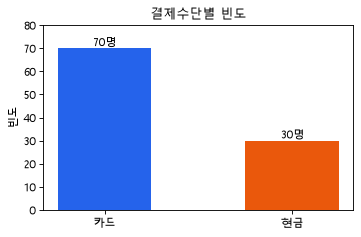

3개 합: 100 | 8개 합: 100 | 8개 중 1등: A


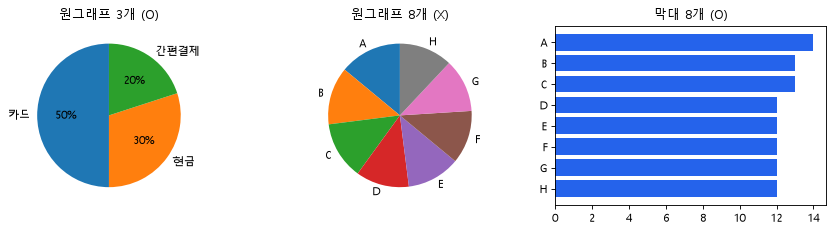

In [29]:
# ---------- 6-1 ----------
# 결제수단 100건: 막대그래프로 범주별 개수 · 비율 (강의 53 ~ 59쪽)
# 왜 · 범주형 변수는 막대로 개수와 비율을 함께 보여 주기 위해
method = pd.Series(["카드"] * 70 + ["현금"] * 30)                      # 범주형 1개
cnt = method.value_counts()                                            # 범주 → 개수
print("개수:", cnt.to_dict(), "| 비율:", (cnt / cnt.sum()).to_dict())  # 개수 · 비율


fig, ax = plt.subplots(figsize=(5, 3))                                         # 한 칸
bars = ax.bar(cnt.index, cnt.values, color=["#2563eb", "#ea580c"], width=0.5)  # 막대 사이 간격
ax.bar_label(bars, labels=[f"{v}명" for v in cnt.values])                      # 막대 위 숫자
ax.set_ylim(0, 80)                                                             # 세로축 0부터
ax.set_ylabel("빈도")                                                          # 세로 = 개수
ax.set_title("결제수단별 빈도")                                                # 무엇을 셌는지
plt.show()                                                                     # 그림 출력


# ---------- 6-2 ----------
# 원그래프 vs 막대그래프: 3개일 때와 8개일 때 (강의 61 · 66쪽)
# 왜 · 항목이 많아지면 원그래프가 비교하기 어려워지는 것을 보이기 위해
share = pd.Series({"카드": 50, "현금": 30, "간편결제": 20})                 # 강의 61쪽 비율
many = pd.Series([14, 13, 13, 12, 12, 12, 12, 12], index=list("ABCDEFGH"))  # 비슷한 8개
print("3개 합:", share.sum(), "| 8개 합:", many.sum(), "| 8개 중 1등:", many.idxmax())  # 합 100%


fig, axes = plt.subplots(1, 3, figsize=(11, 3))                     # 가로 3칸
axes[0].pie(share, labels=share.index, autopct="%d%%", startangle=90)  # 3개 → 비율이 잘 보임
axes[0].set_title("원그래프 3개 (O)")                               # 4 ~ 5개 이하
axes[1].pie(many, labels=many.index, startangle=90)                 # 8개 → 조각 크기 비교가 어려움
axes[1].set_title("원그래프 8개 (X)")                               # 각도 착시
axes[2].barh(many.index[::-1], many.values[::-1], color="#2563eb")  # 같은 8개를 막대로
axes[2].set_title("막대 8개 (O)")                                   # 길이 비교는 쉬움
plt.tight_layout()                                                  # 칸 간격 정리
plt.show()                                                          # 그림 출력

**실행 흐름**

1. 7-1 두 반 박스플롯
2. 7-2 극단값 전 · 후 비교

반 A | 중앙값 75.2 | IQR 4.5 | 이상점 후보 []
반 B | 중앙값 69.9 | IQR 16.4 | 이상점 후보 [105.7, 107.5]


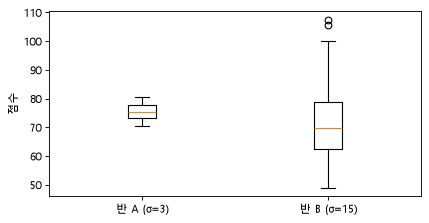

기본 | 평균 65.16 | 중앙값 64.85 | 표준편차 3.41
양쪽 추가 | 평균 65.15 | 중앙값 64.85 | 표준편차 8.33
한쪽 추가 | 평균 66.77 | 중앙값 65.10 | 표준편차 7.94
fence 55.5 ~ 74.3


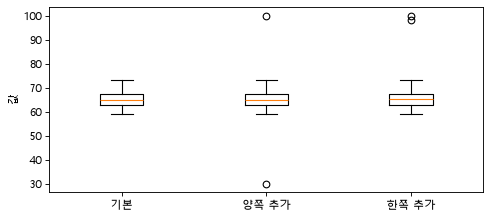

In [30]:
# ---------- 7-1 ----------
# 반 A vs 반 B 박스플롯 (강의 68 · 75 · 80쪽) — 4-2의 두 반
# 왜 · 평균이 같은 두 반의 퍼짐 차이를 한눈에 비교하기 위해
def five(s):                                                    # 다섯 숫자 + fence
    q1, q3 = np.percentile(s, [25, 75])                         # 사분위수
    iqr = q3 - q1                                               # 박스 길이
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr                     # fence
    out = s[(s < lo) | (s > hi)]                                # fence 밖 = 이상점 후보
    return round(np.median(s), 1), round(iqr, 1), out.tolist()  # 중앙값 · IQR · 후보


for name, s in [("반 A", class_a), ("반 B", class_b)]:               # 두 반
    med, iqr, out = five(s)                                          # 요약
    print(f"{name} | 중앙값 {med} | IQR {iqr} | 이상점 후보 {out}")  # 박스 길이 비교


fig, ax = plt.subplots(figsize=(6, 3))                                     # 한 칸
ax.boxplot([class_a, class_b], tick_labels=["반 A (σ=3)", "반 B (σ=15)"])  # 상자 = Q1 ~ Q3
ax.set_ylabel("점수")                                                      # 세로 = 값
plt.show()                                                                 # 그림 출력


# ---------- 7-2 ----------
# 극단값 후보를 넣기 전 · 후 (강의 81 · 82쪽): 양쪽에 하나씩 vs 한쪽에만
# 왜 · 극단값 위치에 따라 박스플롯이 어떻게 바뀌는지 확인하기 위해
base = rng.normal(65, 3, 40).round(1)  # 점수 40개
both = np.r_[base, [100, 30]]          # 아주 큰 값 + 아주 작은 값
one = np.r_[base, [100, 98]]           # 큰 값만 두 개
for name, s in [("기본", base), ("양쪽 추가", both), ("한쪽 추가", one)]:  # 세 경우
    # 비교
    print(f"{name} | 평균 {s.mean():.2f} | 중앙값 {np.median(s):.2f} | 표준편차 {s.std():.2f}")


q1, q3 = np.percentile(both, [25, 75])                                   # 양쪽 추가 후 사분위수
print(f"fence {q1 - 1.5 * (q3 - q1):.1f} ~ {q3 + 1.5 * (q3 - q1):.1f}")  # 이 밖이 점으로 표시


fig, ax = plt.subplots(figsize=(7, 3))                                         # 한 칸
ax.boxplot([base, both, one], tick_labels=["기본", "양쪽 추가", "한쪽 추가"])  # 상자는 거의 그대로
ax.set_ylabel("값")                                                            # 세로 = 값
plt.show()                                                                     # 그림 출력

**실행 흐름**

1. 8-1 산점도
2. 8-2 꺾은선 · 이동 평균
3. 8-3 히트맵

상관계수 | 예외 없음 0.984 | 예외 포함 0.832


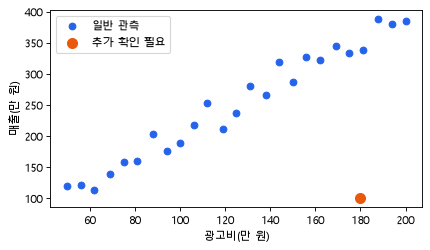

평일 평균: 992.4 | 주말 평균: 1335.2
빠진 날짜: 0 개


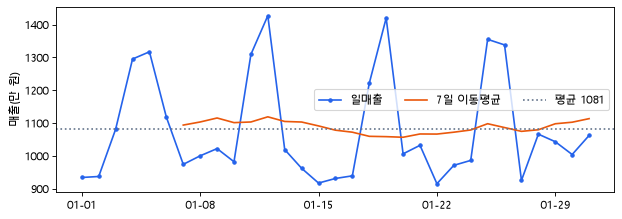

지역별 최고 달: {'서울': '12월', '부산': '8월', '대구': '4월'}


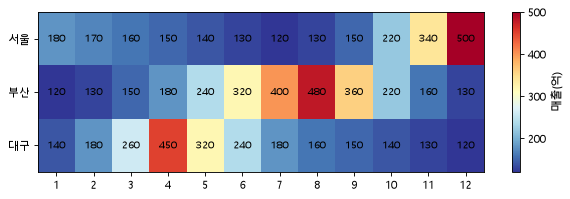

In [31]:
# ---------- 8-1 ----------
# 광고비(만 원) vs 매출(만 원) 25개월 + 예외 1개월 (강의 89 · 96쪽)
# 왜 · 두 수치 변수의 관계와 예외 점을 산점도로 보기 위해
ad = np.linspace(50, 200, 25).round()                        # 광고비 50 ~ 200
sales = (2 * ad + rng.normal(0, 15, 25)).round()             # 대체로 광고비의 2배
r = np.corrcoef(ad, sales)[0, 1]                             # 상관계수 (선형 관계 세기)
ad2, sales2 = np.r_[ad, 180], np.r_[sales, 100]              # 광고비 180인데 매출 100인 달
r2 = np.corrcoef(ad2, sales2)[0, 1]                          # 예외점 포함
print(f"상관계수 | 예외 없음 {r:.3f} | 예외 포함 {r2:.3f}")  # 점 하나로 낮아짐


fig, ax = plt.subplots(figsize=(6, 3.2))                             # 한 칸
ax.scatter(ad, sales, color="#2563eb", label="일반 관측")            # 점 1개 = 1개월
ax.scatter(180, 100, color="#ea580c", s=80, label="추가 확인 필요")  # 예외점
ax.set_xlabel("광고비(만 원)")                                       # 가로 = 원인 후보
ax.set_ylabel("매출(만 원)")                                         # 세로 = 결과 후보
ax.legend()                                                          # 점 이름
plt.show()                                                           # 그림 출력


# ---------- 8-2 ----------
# 카페 1월 일매출(만 원): 평일 ~1000 · 주말 ~1350 (강의 100 · 107쪽)
# 왜 · 시간에 따른 변화와 요일 패턴을 꺾은선 · 이동 평균으로 보기 위해
day = pd.date_range("2025-01-01", periods=31, freq="D")  # 날짜 31개 · 간격 1일
weekend = day.dayofweek >= 5                             # 토(5) · 일(6)
cafe = pd.Series(np.where(weekend, 1350, 1000) + rng.normal(0, 60, 31), index=day).round()  # 일매출
# 차이
print("평일 평균:", cafe[~weekend].mean().round(1), "| 주말 평균:", cafe[weekend].mean().round(1))
# 간격 확인
print("빠진 날짜:", len(pd.date_range(day.min(), day.max()).difference(cafe.index)), "개")


fig, ax = plt.subplots(figsize=(9, 3))                                  # 가로로 긴 칸 (시간 축)
ax.plot(cafe.index, cafe.values, color="#2563eb", marker="o", ms=3, label="일매출")  # 원래 값
ax.plot(cafe.rolling(7).mean(), color="#ea580c", label="7일 이동평균")  # 요일 효과를 지운 추세
ax.axhline(cafe.mean(), color="#64748b", ls=":", label=f"평균 {cafe.mean():.0f}")  # 전체 평균선
ax.set_ylabel("매출(만 원)")                                            # 세로 = 값
ax.set_xticks(day[::7], day[::7].strftime("%m-%d"))                     # 7일 간격 눈금 (겹침 방지)
ax.legend(ncol=3)                                                       # 선 이름 한 줄
plt.show()                                                              # 그림 출력


# ---------- 8-3 ----------
# 지역 x 월 매출(억) — 강의 112쪽 표 그대로
# 왜 · 행 · 열 두 범주의 값 크기를 색으로 한눈에 비교하기 위해
seoul = [180, 170, 160, 150, 140, 130, 120, 130, 150, 220, 340, 500]        # 1 ~ 12월
busan = [120, 130, 150, 180, 240, 320, 400, 480, 360, 220, 160, 130]        # 1 ~ 12월
daegu = [140, 180, 260, 450, 320, 240, 180, 160, 150, 140, 130, 120]        # 1 ~ 12월
sale = pd.DataFrame([seoul, busan, daegu], index=["서울", "부산", "대구"],  # 행 = 지역
                    columns=range(1, 13))                                   # 열 = 월
# 행마다 최댓값 위치
print("지역별 최고 달:", {k: f"{v}월" for k, v in sale.idxmax(axis=1).items()})


fig, ax = plt.subplots(figsize=(9, 2.6))                                     # 가로로 긴 칸
im = ax.imshow(sale, cmap="RdYlBu_r", aspect="auto")                         # 값 → 색 (빨강 = 큼)
for r in range(3):                                                           # 칸마다 숫자
    for c in range(12):                                                      # 12개월
        ax.text(c, r, sale.iat[r, c], ha="center", va="center", fontsize=9)  # 칸 가운데 값
ax.set_xticks(range(12), sale.columns)                                       # 가로 = 월
ax.set_yticks(range(3), sale.index)                                          # 세로 = 지역
fig.colorbar(im, ax=ax, label="매출(억)")                                    # 범례 = 색 ↔ 값
plt.show()                                                                   # 그림 출력

**실행 흐름**

1. 카페 결제 데이터 만들기
2. 대표값 · 도수분포표
3. 질문별 그래프 4개

{'결제수단': 'str', '요일': 'str', '결제금액': 'float64'}
평균 10661 | 중앙값 9200 | 표준편차 8186
IQR 4800 | 이상점 후보 14건
최빈 구간: [5000, 10000) | 상위 3구간 비율: 0.89


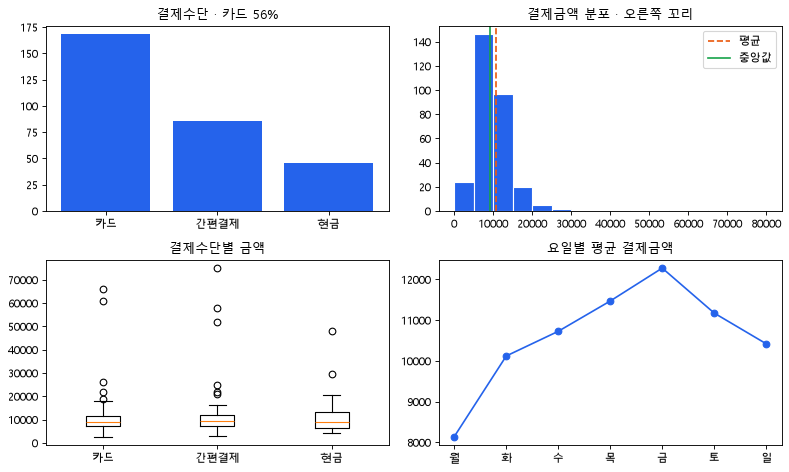

요일별 평균 최고: 금 | 최저: 월


In [32]:
# ---------- 9. 종합 실습 ----------
# 카페 결제 300건: 결제수단(범주) · 요일(범주, 순서) · 결제금액(연속)
# 왜 · 앞에서 배운 요약 · 그래프를 한 데이터에 모두 적용하기 위해
n = 300                                                                        # 결제 건수
method = rng.choice(["카드", "현금", "간편결제"], n, p=[0.6, 0.15, 0.25])      # 범주
weekday = rng.choice(list("월화수목금토일"), n)                                # 순서 있는 범주
big = [52000, 61000, 48000, 75000, 58000, 66000]                               # 단체 주문 6건
price = np.r_[rng.lognormal(np.log(9000), 0.4, n - 6), big].round(-2)          # 대부분 1만 원 안팎
shop = pd.DataFrame({"결제수단": method, "요일": weekday, "결제금액": price})  # 열 3개
print(shop.dtypes.astype(str).to_dict())                                       # 1단계: 유형 확인


# 2단계: 대표값과 퍼짐
# 왜 · 그래프를 그리기 전에 숫자로 먼저 분포를 파악하기 위해
m = shop["결제금액"]                                                              # 연속형 열
print(f"평균 {m.mean():.0f} | 중앙값 {m.median():.0f} | 표준편차 {m.std():.0f}")  # 평균 > 중앙값?
q1, q3 = m.quantile([0.25, 0.75])                                                 # 사분위수
print(f"IQR {q3 - q1:.0f} | 이상점 후보 {(m > q3 + 1.5 * (q3 - q1)).sum()}건")    # 큰 결제


# 3단계: 도수분포표 (5,000원 구간)
# 왜 · 금액 분포를 구간별 개수로 정리하기 위해
# 구간별 개수
table = pd.cut(m, bins=range(0, 80001, 5000), right=False).value_counts().sort_index()
top3 = round(table.nlargest(3).sum() / n, 3)                     # 개수가 많은 세 구간의 비율 합
print("최빈 구간:", table.idxmax(), "| 상위 3구간 비율:", top3)  # 가장 흔한 금액대


# 4단계: 질문마다 맞는 그래프 4개를 한 판에
# 왜 · 질문마다 다른 변수 유형에 맞는 그래프를 고르기 위해
order = list("월화수목금토일")                                           # 요일 순서
fig, axes = plt.subplots(2, 2, figsize=(10, 6))                          # 2행 2열
cnt = shop["결제수단"].value_counts()                                    # 범주 1개 → 막대
axes[0, 0].bar(cnt.index, cnt.values, color="#2563eb")                   # 왼쪽 위 · 개수
axes[0, 0].set_title(f"결제수단 · {cnt.idxmax()} {cnt.max() / n:.0%}")   # 발견한 사실
axes[0, 1].hist(m, bins=range(0, 80001, 5000), color="#2563eb", edgecolor="white")  # 수치 1개
axes[0, 1].axvline(m.mean(), color="#ea580c", ls="--", label="평균")     # 꼬리에 끌린 평균
axes[0, 1].axvline(m.median(), color="#16a34a", label="중앙값")          # 보통 손님
axes[0, 1].legend()                                                      # 선 이름
axes[0, 1].set_title("결제금액 분포 · 오른쪽 꼬리")                      # 오른쪽 위
groups = [m[shop["결제수단"] == k] for k in cnt.index]                   # 범주 + 수치 → 박스플롯
axes[1, 0].boxplot(groups, tick_labels=cnt.index)                        # 결제수단마다 상자 1개
axes[1, 0].set_title("결제수단별 금액")                                  # 왼쪽 아래
by_day = shop.groupby("요일")["결제금액"].mean().reindex(order)          # 순서 + 수치 → 선
axes[1, 1].plot(order, by_day.values, marker="o", color="#2563eb")       # 월 ~ 일 순서
axes[1, 1].set_title("요일별 평균 결제금액")                             # 오른쪽 아래
plt.tight_layout()                                                       # 칸 간격 정리
plt.show()                                                               # 그림 출력
print("요일별 평균 최고:", by_day.idxmax(), "| 최저:", by_day.idxmin())  # 선그래프에서 읽은 값